In [620]:

from numba import njit
import numpy as np
import pandas as pd

from collections import defaultdict

import matplotlib.gridspec as gridspec

import os

from scipy.optimize import fsolve
from scipy.ndimage import zoom
from scipy.ndimage import gaussian_filter
from scipy import interpolate as _itp


import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.transforms import ScaledTranslation
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib as mpl

mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42



font_path = "/Users/tomroeschinger/Library/Fonts/Lucida-Sans-Unicode-Regular.ttf" 
if os.path.exists(font_path):
    font_manager.fontManager.addfont(font_path)
    prop = font_manager.FontProperties(fname=font_path)

mpl.rcParams["font.family"] = "sans-serif",
mpl.rcParams["font.sans-serif"] = prop.get_name()

In [3]:
os.path.exists(font_path)

True

In [4]:
# Get the current property cycle
prop_cycle = plt.rcParams['axes.prop_cycle']

# Extract the colors from the property cycle
colors = prop_cycle.by_key()['color']
colors

['#1f77b4',
 '#ff7f0e',
 '#2ca02c',
 '#d62728',
 '#9467bd',
 '#8c564b',
 '#e377c2',
 '#7f7f7f',
 '#bcbd22',
 '#17becf']

In [5]:

# Register fonts (adjust paths or comment out if missing)
for f in ["fonts/Lucida-Sans-Unicode-Regular.ttf", "fonts/Lucida-Sans-Bold.otf"]:
    try:
        font_manager.fontManager.addfont(f)
    except FileNotFoundError:
        pass
try:
    prop = font_manager.FontProperties(fname="fonts/Lucida-Sans-Unicode-Regular.ttf")
    plt.rcParams["font.family"] = prop.get_name()
except Exception:
    pass

plt.rcParams.update({
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.linewidth": 1.25,
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

# Global constants
gap = 5
l0  = 10
N   = 100000
f0  = 100 * l0 / (2 * N)
n   = 4


In [6]:
# %% Cell 2: Core functions with Numba

def kimura(s, N):
    if abs(s) > 1e-10:
        return (1 - np.exp(-2*s)) / (1 - np.exp(-2*N*s))
    else:
        return 1.0 / N

def g_rate(s, N):
    return N * kimura(s, N)

# %% Cell 2: Core functions with Numba
@njit
def kimura_nb(s, N):
    if abs(s) > 1e-8:
        return (1 - np.exp(-2*s)) / (1 - np.exp(-2*N*s))
    else:
        return 1.0 / N

@njit
def g_rate_nb(s, N):
    return N * kimura_nb(s, N)

@njit
def gamma0_nb(n):
    return 1.0 / n

@njit
def fann_nb(gap, l0, n):
    g0 = gamma0_nb(n)
    return np.log(g0 * np.exp((1 - g0)*(gap/l0)) +
                  (1 - g0)*np.exp(-g0*(gap/l0)))

@njit
def lmin_nb(gap, l0, n):
    return np.ceil(l0*(gap+1) /
                   ((1 - gamma0_nb(n) - (l0/gap)*fann_nb(gap,l0,n))*gap))

@njit
def gamma50_nb(l, gap, l0, n, use_approx=False):
    base = gamma0_nb(n) + l0 / l
    if use_approx:
        return base
    return base + (l - lmin_nb(gap,l0,n)) / (l*(gap/l0)) * fann_nb(gap,l0,n)

@njit
def Fitness_nb(gamma, l, c, gap, l0, f0, n):
    g50 = gamma50_nb(l, gap, l0, n)
    return f0 / (1 + np.exp(-gap*l/l0*(gamma - g50))) - c*l


@njit
def up_nb(gamma, l, kappa, c, gap, l0, f0, n, N):
    if gamma >= 1.0: 
        return 0.0
    df = (Fitness_nb(gamma + 1/l, l, c, gap, l0, f0, n)
        - Fitness_nb(gamma, l, c, gap, l0, f0, n))
    return gamma0_nb(n)/(1-gamma0_nb(n)) * (1-gamma) * (g_rate_nb(df, N) + kappa)

@njit
def um_nb(gamma, l, kappa, c, gap, l0, f0, n, N):
    if gamma <= 0.0: 
        return 0.0
    df = (Fitness_nb(gamma - 1/l, l, c, gap, l0, f0, n)
        - Fitness_nb(gamma, l, c, gap, l0, f0, n))
    return gamma * (g_rate_nb(df, N) + kappa)



# ———————— Selection coefficients ————————

## Edge cases for length mutations
# (k,l) -> (k+1,l+1)
def gamma_pp(g, l):
    return np.minimum((g + 1/l)/(1 + 1/l), 1)

# (k,l) -> (k,l+1)
def gamma_pm(g, l):
    return np.maximum(g /(1 + 1/l), 0)

# (k,l) -> (k,l-1)
def gamma_mp(g, l):
    return np.minimum(g/(1 - 1/l), 1)

# (k,l) -> (k-1,l-1)
def gamma_mm(g, l):
    return np.maximum((g - 1/l)/(1 - 1/l), 0)

def s_pp(g, l, c, gap, l0, f0, n, N):
    """(k,l) → (k+1, l+1)"""
    return (
        Fitness_nb(gamma_pp(g, l), l+1, c, gap, l0, f0, n)
        - Fitness_nb(g,              l, c, gap, l0, f0, n)
    )

def s_pm(g, l,  c, gap, l0, f0, n, N):
    """(k,l) → (k, l+1)"""
    return (
        Fitness_nb(gamma_pm(g, l), l+1, c, gap, l0, f0, n)
        - Fitness_nb(g,               l, c, gap, l0, f0, n)
    )

def s_mm(g, l, c, gap, l0, f0, n, N):
    """(k,l) → (k-1, l-1)"""
    return (
        Fitness_nb(gamma_mm(g, l), l-1, c, gap, l0, f0, n)
        - Fitness_nb(g,               l,   c, gap, l0, f0, n)
    )

def s_mp(g, l, c, gap, l0, f0, n, N):
    """(k,l) → (k, l-1)"""
    return (
        Fitness_nb(gamma_mp(g, l), l-1, c, gap, l0, f0, n)
        - Fitness_nb(g,               l,   c, gap, l0, f0, n)
    )

# ———————— Substitution rates ————————
def v_pp(g, l, c, gap, l0, f0, n, N):
    """Rate for (k,l)→(k+1,l+1)."""
    return gamma0_nb(n) * g_rate_nb(s_pp(g, l, c, gap, l0, f0, n, N), N)

def v_pm(g, l, c, gap, l0, f0, n, N):
    """Rate for (k,l)→(k, l+1)."""
    return (1.0 - gamma0_nb(n)) * g_rate_nb(s_pm(g, l, c, gap, l0, f0, n, N), N)

def v_plus(g, l, c, gap, l0, f0, n, N):
    """Total increase rate."""
    return v_pp(g, l, c, gap, l0, f0, n, N) + v_pm(g, l, c, gap, l0, f0, n, N)


def v_plus_star(l, kappa, c, gap, l0, f0, n, N):
    """Evaluate v_plus at γ*."""
    gstar = gamma_star(l, kappa, c, gap, l0, f0, n, N)
    return v_plus(gstar, l, c, gap, l0, f0, n, N)

def v_mm(g, l, c, gap, l0, f0, n, N):
    """Rate for (k,l)→(k-1,l-1)."""
    return g * g_rate_nb(s_mm(g, l, c, gap, l0, f0, n, N), N)

def v_mp(g, l, c, gap, l0, f0, n, N):
    """Rate for (k,l)→(k, l-1)."""
    return (1.0 - g) * g_rate_nb(s_mp(g, l, c, gap, l0, f0, n, N), N)

def v_minus(g, l, c, gap, l0, f0, n, N):
    """Total decrease rate."""
    return v_mm(g, l, c, gap, l0, f0, n, N) + v_mp(g, l, c, gap, l0, f0, n, N)

def v_minus_star(l, kappa, c, gap, l0, f0, n, N):
    """Evaluate v_minus at γ*."""
    gstar = gamma_star(l, kappa, c, gap, l0, f0, n, N)
    return v_minus(gstar, l, c, gap, l0, f0, n, N)

# ———————— Inverse substitution probability ————————
def ginv(u, N=N):
    """
    Solve for x such that g_rate_nb(x, N) == u.
    """
    sol = fsolve(lambda x: g_rate(x, N)/N - u, 1/N)
    return float(sol[0])

# ———————— Effective selective coefficients ————————
def seffplus(l, kappa, c, gap, l0, f0, n, N):
    """Effective s for length increase at ℓ."""
    return ginv(v_plus_star(l, kappa, c, gap, l0, f0, n, N), N)

def seffminus(l, kappa, c, gap, l0, f0, n, N):
    """Effective s for length decrease at ℓ."""
    return ginv(v_minus_star(l, kappa, c, gap, l0, f0, n, N), N)

def seff(l, kappa, c, gap, l0, f0, n, N):
    """Log‐ratio of forward/back rates around ℓ."""
    return np.log(
        v_plus_star(l - 1, kappa, c, gap, l0, f0, n, N)
        / v_minus_star(l,     kappa, c, gap, l0, f0, n, N)
    )


# %% Cell 4: Ψ_k loop (Numba)
@njit
def Psi_k_nb(l, kappa, c, gap, l0, f0, n, N):
    plist = np.zeros(l+1)
    for i in range(1, l+1):
        g_prev = (i-1)/l
        g_curr = i/l
        upv = up_nb(g_prev, l, kappa, c, gap, l0, f0, n, N)
        umv = um_nb(g_curr, l, kappa, c, gap, l0, f0, n, N)
        if upv == 0:
            upv = 10**-100
        if umv == 0:
            umv = 10**-100
            
        plist[i] = plist[i-1] + np.log(upv/umv)
    return plist

# %% Cell 5: γ* & lstar (Python using Numba routines)
def gamma_star(l, kappa, c, gap=gap, l0=l0, f0=f0, n=n, N=N):
    plist = Psi_k_nb(l, kappa, c, gap, l0, f0, n, N)
    if gamma50_nb(l, gap, l0, n, False) < 1.0:
        idx = np.argmax(plist)
        if idx < l:
            x = np.array([(idx+i-1)/l for i in range(3)])
            y = plist[idx-1:idx+2]
            a2, a1, _ = np.polyfit(x, y, 2)
            return -a1/(2*a2)
    return 1.0


In [7]:

def lstar(kappa, c, N=N, lmax=300):
    gamma_list = [gamma_star(l, kappa,c) for l in range(1, lmax+1)]
    functional = [(gamma50_nb(l, gap, l0, n, False) < gamma_list[i] <= 1.0)
                  for i, l in enumerate(range(1, lmax+1))]
    lm_idx = next(i for i, ok in enumerate(functional) if ok)
    lm = lm_idx + 1
    flist = np.cumsum([
        np.log(
            v_plus(gamma_star(l-1, kappa, c), l-1, c, gap, l0, f0, n, N) /
            v_minus(gamma_star(l, kappa, c), l, c, gap, l0, f0, n, N)
        )
        for l in range(lm, lmax+1)
    ])
    lst = np.argmax(flist) + lm
    return lm, lst, flist

## Bigger range of parameters

In [8]:

# %% Cell 6: Build DataFrame in one comprehension
import itertools

kappa_vals = np.logspace(-2, np.log10(30), num=50)
c_vals     = np.logspace(-2, 1, num=50)

def make_record(kappa, c_raw):
    c0 = c_raw/(2*N)

    lm, lst, flist = lstar(kappa, c0, N, 300)
    gst = gamma_star(lst, kappa, c0)
    s = f0 - Fitness_nb(gst, lst, 0, gap, l0, f0, n)

    if gst == 1.0:
        um_val, up_val = 0.0, -1.0
    else:
        um_val = um_nb(gst, lst, 0.0, c0, gap, l0, f0, n, N)
        up_val = up_nb(gst, lst, 0.0, c0, gap, l0, f0, n, N)

    return {
        "kappa":      kappa,
        "c":          c_raw,
        "gamma_star": gst,
        "l_star":     lst,
        "um":         um_val,
        "up":         up_val,
        "flist":      flist,
        "lm":         lm,
        "s":          s
    }

# Uncomment to build the full DataFrame (may take time)
records = [make_record(k, c) for k, c in itertools.product(kappa_vals, c_vals)]
df = pd.DataFrame.from_records(records)


KeyboardInterrupt: 

/var/folders/67/2rd1gct91876bvjs_7ny9rcw0000gn/T/ipykernel_81760/106989622.py:51: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


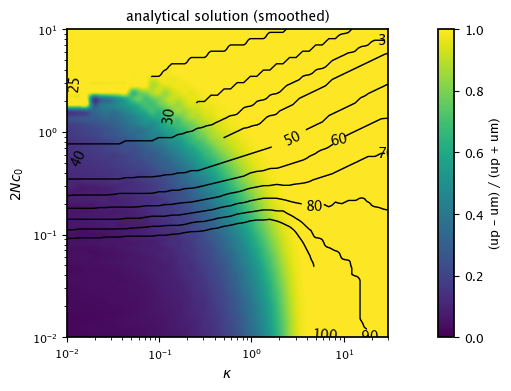

In [ ]:


# 1) Compute normalized difference
df["delta_ud"] = (df["up"] - df["um"]) / (df["up"] + df["um"])

# 2) Pivot to matrices
pivot_delta = df.pivot(index="c", columns="kappa", values="delta_ud")
pivot_lstar = df.pivot(index="c", columns="kappa", values="l_star")

# 3) Original grid and values
C_vals = pivot_delta.index.values
K_vals = pivot_delta.columns.values
Z_delta = pivot_delta.values
Z_lstar = pivot_lstar.values

# 4) Interpolate using zoom for smoothing (factor=4 means 4x finer grid)
zoom_factor = 50
Z_delta_smooth = zoom(Z_delta, zoom_factor, order=3)  # cubic interpolation
Z_lstar_smooth = zoom(Z_lstar, zoom_factor, order=1)  # linear interpolation for contours

# New finer grid
C_fine = np.logspace(np.log10(C_vals.min()), np.log10(C_vals.max()), Z_delta_smooth.shape[0])
K_fine = np.logspace(np.log10(K_vals.min()), np.log10(K_vals.max()), Z_delta_smooth.shape[1])
K_grid, C_grid = np.meshgrid(K_fine, C_fine)

# 5) Plot
fig = plt.figure(figsize=(5, 4), dpi=100)
gs  = fig.add_gridspec(1, 2, width_ratios=[20, 1], wspace=0.3)
ax1 = fig.add_subplot(gs[0,0])
cax = fig.add_subplot(gs[0,1])

# Smoothed heatmap
pcm = ax1.pcolormesh(K_grid, C_grid, Z_delta_smooth, cmap="viridis", vmin=0, vmax=1)

# Optional smoothed contour lines for l_star
levels = np.arange(20, 100, 10)
levels = [15, 20, 25, 30, 35, 40, 50, 60, 70, 80, 90, 100]
cs = ax1.contour(K_grid, C_grid, Z_lstar_smooth, levels=levels, colors="black", linewidths=1)
ax1.clabel(cs, inline=True)# fmt="%d", fontsize=8)

# Axes, labels
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlabel(r"$\kappa$", fontsize=10)
ax1.set_ylabel(r"$2Nc_0$", fontsize=10)
ax1.set_title("analytical solution (smoothed)", fontsize=10)

# Colorbar
cb = fig.colorbar(pcm, cax=cax)
cb.set_label("(up – um) / (up + um)", fontsize=9)
cb.ax.tick_params(labelsize=9)

plt.tight_layout()
plt.show()

#fig.savefig("phase_diagram.pdf")

/var/folders/67/2rd1gct91876bvjs_7ny9rcw0000gn/T/ipykernel_81760/1211149718.py:46: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


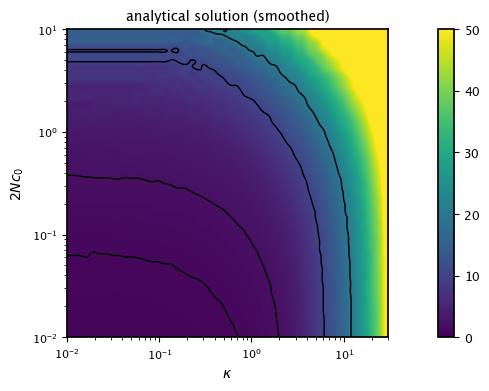

In [ ]:
# 2) Pivot to matrices
pivot_delta = df.pivot(index="c", columns="kappa", values="s")
pivot_lstar = df.pivot(index="c", columns="kappa", values="l_star")

# 3) Original grid and values
C_vals = pivot_delta.index.values
K_vals = pivot_delta.columns.values
Z_delta = np.round(pivot_delta.values, 7)
Z_lstar = pivot_lstar.values

# 4) Interpolate using zoom for smoothing (factor=4 means 4x finer grid)
zoom_factor = 50
Z_delta_smooth = zoom(Z_delta, zoom_factor, order=3)  # cubic interpolation
Z_lstar_smooth = zoom(Z_lstar, zoom_factor, order=1)  # linear interpolation for contours

# New finer grid
C_fine = np.logspace(np.log10(C_vals.min()), np.log10(C_vals.max()), Z_delta_smooth.shape[0])
K_fine = np.logspace(np.log10(K_vals.min()), np.log10(K_vals.max()), Z_delta_smooth.shape[1])
K_grid, C_grid = np.meshgrid(K_fine, C_fine)

# 5) Plot
fig = plt.figure(figsize=(5, 4), dpi=100)
gs  = fig.add_gridspec(1, 2, width_ratios=[20, 1], wspace=0.3)
ax1 = fig.add_subplot(gs[0,0])
cax = fig.add_subplot(gs[0,1])

# Smoothed heatmap
pcm = ax1.pcolormesh(K_grid, C_grid, 2*N*Z_delta_smooth*gap/l0, cmap="viridis", vmin=0, vmax=50)

# Optional smoothed contour lines for l_star
levels = [1, 2, 10, 20]
cs = ax1.contour(K_grid, C_grid, 2*N*Z_delta_smooth*gap/l0, levels=levels, colors="black", linewidths=1)
#ax1.clabel(cs, inline=True)# fmt="%d", fontsize=8)

# Axes, labels
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlabel(r"$\kappa$", fontsize=10)
ax1.set_ylabel(r"$2Nc_0$", fontsize=10)
ax1.set_title("analytical solution (smoothed)", fontsize=10)

# Colorbar
cb = fig.colorbar(pcm, cax=cax)
cb.ax.tick_params(labelsize=9)

plt.tight_layout()
plt.show()

#fig.savefig("phase_diagram.pdf")

In [ ]:
np.min(df['s'] * 2 * N * gap/l0)

np.float64(0.5988336622482666)

In [138]:
def redraw_spline_contours_from_segs(ax, contourset, smooth=0.001, densify=4, **line_kw):
    """
    Redraw contours using cubic B-splines based on the raw segment arrays (cs.allsegs),
    avoiding reliance on cs.collections.
    """
    from scipy import interpolate as _itp

    # contourset.allsegs is a list (levels) of lists (segments) of Nx2 arrays
    for level_segs in contourset.allsegs:
        if not level_segs:
            continue
        for seg in level_segs:
            if seg is None or len(seg) < 8:
                continue
            x, y = seg[:, 0], seg[:, 1]
            # parametric cubic spline through the polyline
            try:
                tck, _ = _itp.splprep([x, y], s=smooth, per=False)
                u = np.linspace(0, 1, len(x) * densify)
                xs, ys = _itp.splev(u, tck)
                ax.plot(xs, ys, **line_kw)
            except Exception:
                # fall back to the raw segment if spline fails (rare, degenerate segments)
                ax.plot(x, y, **line_kw)


## smaller range of parameters

In [84]:

# %% Cell 6: Build DataFrame in one comprehension
import itertools

kappa_vals = np.logspace(np.log10(0.03), np.log10(30), num=50)
c_vals     = np.logspace(np.log10(0.03), 1, num=50)

def make_record(kappa, c_raw):
    c0 = c_raw/(2*N)

    lm, lst, flist = lstar(kappa, c0, N, 300)
    gst = gamma_star(lst, kappa, c0)
    s = (f0 - Fitness_nb(gst, lst, 0, gap, l0, f0, n))

    if gst == 1.0:
        um_val, up_val = 0.0, -1.0
    else:
        um_val = um_nb(gst, lst, 0.0, c0, gap, l0, f0, n, N)
        up_val = up_nb(gst, lst, 0.0, c0, gap, l0, f0, n, N)

    return {
        "kappa":      kappa,
        "c":          c_raw,
        "gamma_star": gst,
        "l_star":     lst,
        "um":         um_val,
        "up":         up_val,
        "flist":      flist,
        "lm":         lm,
        's':          s
    }

# Uncomment to build the full DataFrame (may take time)
records = [make_record(k, c) for k, c in itertools.product(kappa_vals, c_vals)]
df = pd.DataFrame.from_records(records)


/var/folders/67/2rd1gct91876bvjs_7ny9rcw0000gn/T/ipykernel_81760/3900410409.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


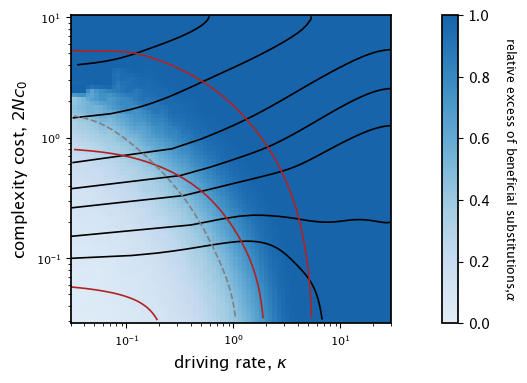

In [139]:
df["delta_ud"] = (df["up"] - df["um"]) / (df["up"] + df["um"])

# 2) Pivot to matrices
pivot_delta = df.pivot(index="c", columns="kappa", values="delta_ud")
pivot_s = df.pivot(index="c", columns="kappa", values="s")
pivot_lstar = df.pivot(index="c", columns="kappa", values="l_star")

# 3) Original grid and values
C_vals = pivot_delta.index.values
K_vals = pivot_delta.columns.values
Z_delta = pivot_delta.values
Z_s = pivot_s.values
Z_lstar = pivot_lstar.values

# 4) Interpolate using zoom for smoothing (factor=4 means 4x finer grid)
zoom_factor = 1.5
Z_delta_smooth = zoom(Z_delta, zoom_factor, order=3)  # cubic interpolation
Z_s_smooth = zoom(Z_s, zoom_factor, order=1)  # linear interpolation for contours
Z_lstar_smooth = zoom(Z_lstar, zoom_factor, order=1)  # linear interpolation for contours

Zl = np.array(Z_lstar_smooth, dtype=float)
Zl[~np.isfinite(Zl)] = np.nan   
Zl = gaussian_filter(Zl, sigma=5)

Zs = np.array(Z_s_smooth, dtype=float)
Zs[~np.isfinite(Zs)] = np.nan   
Zs = gaussian_filter(Zs, sigma=5)

Zd = np.array(Z_delta_smooth, dtype=float)
Zd[~np.isfinite(Zd)] = np.nan   
Zd = gaussian_filter(Zd, sigma=5)

# New finer grid
C_fine = np.logspace(np.log10(C_vals.min()), np.log10(C_vals.max()), Z_delta_smooth.shape[0])
K_fine = np.logspace(np.log10(K_vals.min()), np.log10(K_vals.max()), Z_delta_smooth.shape[1])
K_grid, C_grid = np.meshgrid(K_fine, C_fine)

# 5) Plot
fig = plt.figure(figsize=(5, 4))#, dpi=100)
gs  = fig.add_gridspec(1, 2, width_ratios=[20, 1], wspace=0.3)
ax1 = fig.add_subplot(gs[0,0])
cax = fig.add_subplot(gs[0,1])

# Smoothed heatmap
Blues_lighter = mpl.colors.LinearSegmentedColormap.from_list(
    "Blues_lighter",
    mpl.cm.Blues(np.linspace(0.1, 0.8, 256))  # shift start toward lighter tones
)
pcm = ax1.pcolormesh(K_grid, C_grid, Z_delta_smooth, cmap=Blues_lighter, vmin=0, vmax=1, 
    shading="nearest",      # avoid averaged edges that cause gaps
    edgecolors="none",      # no stroke between cells
    linewidth=0.0,          # belt-and-suspenders
    antialiased=False,      # prevent extra edge AA
)

pcm.set_rasterized(True)

# Optional smoothed contour lines for l_star
levels = np.arange(20, 100, 10)
levels = [15, 20, 25, 30 , 40, 50, 60, 80, 100]
cs = ax1.contour(K_grid, C_grid, Zl, levels=levels, colors="black", linewidths=0)

levels = [1, 3, 10]
cs2 = ax1.contour(K_grid, C_grid, Zs * 2 * N * gap/l0, levels=levels, colors="gray", linewidths=0)
#ax1.clabel(cs, inline=True)# fmt="%d", fontsize=8)

levels = [0.5]
cs3 = ax1.contour(K_grid, C_grid, Zd, levels=levels, colors="orange", linewidths=0)


# Axes, labels
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlabel("driving rate, " + r"$\kappa$", fontsize=12)
ax1.set_ylabel("complexity cost, " + r"$2Nc_0$", fontsize=12)
#ax1.set_title("analytical solution (smoothed)", fontsize=10)

# Colorbar
cb = fig.colorbar(pcm, cax=cax)
cb.set_label("relative excess of beneficial substitutions," r"$\alpha$", fontsize=9, rotation=270, labelpad=20)
cb.ax.tick_params(labelsize=10)



redraw_spline_contours_from_segs(ax1, cs, smooth=0.0001, densify=1, color="black", linewidth=1.2)
redraw_spline_contours_from_segs(ax1, cs2, smooth=0.0001, densify=1, color="#B22222", linewidth=1.2)
redraw_spline_contours_from_segs(ax1, cs3, smooth=0.0001, densify=1, color="gray", linewidth=1.2, linestyle='--')


ax1.set_xlim(np.min(kappa_vals), np.max(kappa_vals))
ax1.grid(False)
plt.tight_layout()
plt.show()

fig.savefig("phase_diagram_w_selection.pdf")

/var/folders/67/2rd1gct91876bvjs_7ny9rcw0000gn/T/ipykernel_81760/4225179484.py:72: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


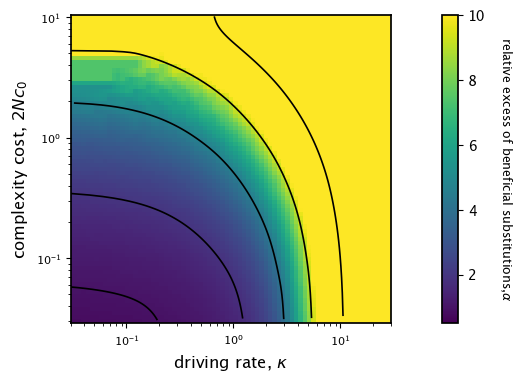

In [102]:
df["delta_ud"] = (df["up"] - df["um"]) / (df["up"] + df["um"])

# 2) Pivot to matrices
pivot_delta = df.pivot(index="c", columns="kappa", values="delta_ud")
pivot_s = df.pivot(index="c", columns="kappa", values="s")
pivot_lstar = df.pivot(index="c", columns="kappa", values="l_star")

# 3) Original grid and values
C_vals = pivot_delta.index.values
K_vals = pivot_delta.columns.values
Z_delta = pivot_delta.values
Z_s = pivot_s.values
Z_lstar = pivot_lstar.values

# 4) Interpolate using zoom for smoothing (factor=4 means 4x finer grid)
zoom_factor = 1.5
Z_delta_smooth = zoom(Z_delta, zoom_factor, order=3)  # cubic interpolation
Z_s_smooth = zoom(Z_s, zoom_factor, order=1)  # linear interpolation for contours
Z_lstar_smooth = zoom(Z_lstar, zoom_factor, order=1)  # linear interpolation for contours

Zl = np.array(Z_lstar_smooth, dtype=float)
Zl[~np.isfinite(Zl)] = np.nan   
Zl = gaussian_filter(Zl, sigma=5)

Zs = np.array(Z_s_smooth, dtype=float)
Zs[~np.isfinite(Zs)] = np.nan   
Zs = gaussian_filter(Zs, sigma=5)

# New finer grid
C_fine = np.logspace(np.log10(C_vals.min()), np.log10(C_vals.max()), Z_delta_smooth.shape[0])
K_fine = np.logspace(np.log10(K_vals.min()), np.log10(K_vals.max()), Z_delta_smooth.shape[1])
K_grid, C_grid = np.meshgrid(K_fine, C_fine)

# 5) Plot
fig = plt.figure(figsize=(5, 4))#, dpi=100)
gs  = fig.add_gridspec(1, 2, width_ratios=[20, 1], wspace=0.3)
ax1 = fig.add_subplot(gs[0,0])
cax = fig.add_subplot(gs[0,1])

# Smoothed heatmap
pcm = ax1.pcolormesh(K_grid, C_grid, Z_s_smooth * 2 * N * gap/l0, cmap="viridis", shading="auto", vmin=0.5, vmax=10)

# Optional smoothed contour lines for l_star
levels = np.arange(20, 100, 10)
levels = [15, 20, 25, 30, 35, 40, 50, 60, 70, 80, 100]
#cs = ax1.contour(K_grid, C_grid, Zl, levels=levels, colors="black", linewidths=0)

levels = [1, 2, 5, 10, 20]
cs2 = ax1.contour(K_grid, C_grid, Zs * 2 * N * gap/l0, levels=levels, colors="gray", linewidths=0)
#ax1.clabel(cs, inline=True)# fmt="%d", fontsize=8)

# Axes, labels
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlabel("driving rate, " + r"$\kappa$", fontsize=12)
ax1.set_ylabel("complexity cost, " + r"$2Nc_0$", fontsize=12)
#ax1.set_title("analytical solution (smoothed)", fontsize=10)

# Colorbar
cb = fig.colorbar(pcm, cax=cax)
cb.set_label("relative excess of beneficial substitutions," r"$\alpha$", fontsize=9, rotation=270, labelpad=20)
cb.ax.tick_params(labelsize=10)



#redraw_spline_contours_from_segs(ax1, cs, smooth=0.0001, densify=1, color="black", linewidth=1.2)
redraw_spline_contours_from_segs(ax1, cs2, smooth=0.0001, densify=1, color="black", linewidth=1.2)


ax1.set_xlim(np.min(kappa_vals), np.max(kappa_vals))
ax1.grid(False)
plt.tight_layout()
plt.show()

#fig.savefig("phase_diagram.pdf")

/var/folders/67/2rd1gct91876bvjs_7ny9rcw0000gn/T/ipykernel_81760/2985191526.py:57: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


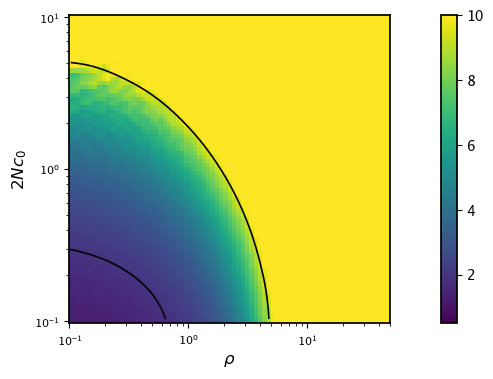

In [56]:
# 2) Pivot to matrices
pivot_delta = df.pivot(index="c", columns="kappa", values="s")

# 3) Original grid and values
C_vals = pivot_delta.index.values
K_vals = pivot_delta.columns.values
Z_delta = pivot_delta.values

# 4) Interpolate using zoom for smoothing (factor=4 means 4x finer grid)
zoom_factor = 1.5
Z_delta_smooth = zoom(Z_delta, zoom_factor, order=3)  # cubic interpolation

Zl = np.array(Z_delta_smooth, dtype=float)
Zl[~np.isfinite(Zl)] = np.nan   

Zl = gaussian_filter(Zl, sigma=5)

# New finer grid
C_fine = np.logspace(np.log10(C_vals.min()), np.log10(C_vals.max()), Z_delta_smooth.shape[0])
K_fine = np.logspace(np.log10(K_vals.min()), np.log10(K_vals.max()), Z_delta_smooth.shape[1])
K_grid, C_grid = np.meshgrid(K_fine, C_fine)

# 5) Plot
fig = plt.figure(figsize=(5, 4))#, dpi=100)
gs  = fig.add_gridspec(1, 2, width_ratios=[20, 1], wspace=0.3)
ax1 = fig.add_subplot(gs[0,0])
cax = fig.add_subplot(gs[0,1])

# Smoothed heatmap
pcm = ax1.pcolormesh(K_grid, C_grid, Z_delta_smooth*2*N*gap/l0, cmap="viridis",shading="auto", vmin = 0.5, vmax=10)

# Optional smoothed contour lines for l_star
#levels = np.arange(20, 100, 10)
#levels = [15, 20, 25, 30, 35, 40, 50, 60, 70, 80]
levels = [1, 2, 10]
cs = ax1.contour(K_grid, C_grid, Zl*2*N*gap/l0, levels=levels, colors="black", linewidths=0)
#ax1.clabel(cs, inline=True)# fmt="%d", fontsize=8)

# Axes, labels
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlabel(r"$\rho$", fontsize=12)
ax1.set_ylabel(r"$2Nc_0$", fontsize=12)
#ax1.set_title("analytical solution (smoothed)", fontsize=10)

# Colorbar
cb = fig.colorbar(pcm, cax=cax)
cb.ax.tick_params(labelsize=10)



redraw_spline_contours_from_segs(ax1, cs, smooth=0.0001, densify=1, color="black", linewidth=1.2)


ax1.set_xlim(np.min(kappa_vals), np.max(kappa_vals))
ax1.grid(False)
plt.tight_layout()
plt.show()

#fig.savefig("phase_diagram.pdf")

In [44]:
df['s'] * 2 * N / 2

0         1.241872
1         1.303177
2         1.324631
3         1.382107
4         1.444189
           ...    
2495    150.991309
2496    150.991309
2497    150.991309
2498    150.991309
2499    150.991309
Name: s, Length: 2500, dtype: float64

IndexError: index 5 is out of bounds for axis 0 with size 4

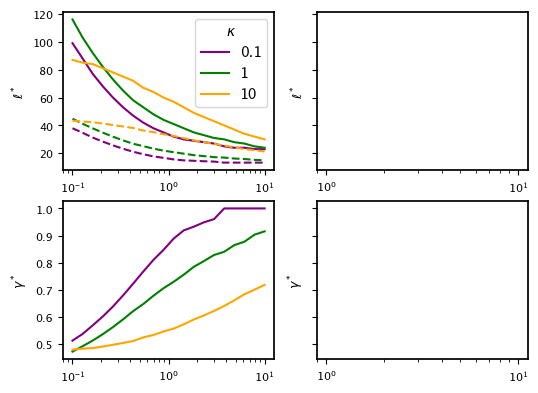

In [12]:
fig, ax_arr = plt.subplots(2, 2, figsize=(6, 4.5), sharey='row')
ax = np.ravel(ax_arr)
ax[0].set_xscale('log')
#ax[0].set_xlabel(r'$2Nc_0$')
ax[0].set_ylabel(r'$\ell^*$')

#ax[2].set_xlabel(r'$2Nc_0$')
ax[2].set_ylabel(r'$\gamma^*$')
ax[2].set_xscale('log')

# #ax[4].set_xlabel(r'$2Nc_0$')
# ax[4].set_ylabel(r'$A$')
# ax[4].set_xscale('log')

# ax[6].set_xlabel(r'$2Nc_0$')
# ax[6].set_ylabel(r'$v_\mathrm{tot}$')
# ax[6].set_xscale('log')

c_arr = np.logspace(-1, 1, num=20)

for color, k in zip(['purple', 'green', 'orange'], [0.1 , 1, 10]):
    
    l_list = []
    l_F = []
    g_list = []
    A_list = []
    v_arr = []
    for _c in c_arr:
        c = _c / (2*N)
        lm, lst, _ = lstar(k, c, N=N, lmax=1000)
        
        x = range(lm, 1000)
        y = [Fitness_nb(gamma_star(l, k, c), l, c, gap, l0, f0, n) for l in x]
        gst = gamma_star(lst, k, c)
        v_arr.append(v_plus_star(lst, k, c, gap, l0, f0, n, N) + v_minus_star(lst, k, c, gap, l0, f0, n, N))
        g_list.append(gst)
        l_list.append(lst)
        l_F.append(np.argmax(y) + lm)
        A_list.append(lst * (1-gst))
    ax[0].plot(c_arr, l_list, label=k, color=color)
    ax[0].plot(c_arr, l0 / (np.array(g_list) - 1/4), color=color, ls='--') 
    #ax[1].plot(np.logspace(-1, 1, num=30), l_F, color=color, ls='--') 
    ax[2].plot(c_arr, g_list, color=color) 
    #ax[4].plot(c_arr, A_list, color=color) 
    #ax[6].plot(c_arr, v_arr, color=color) 

ax[0].legend(title=r'$\kappa$')
#ax[0].set_ylim(0, 200)
#ax[1].set_ylim(0, 200)


ax[1].set_xscale('log')
#ax[1].set_xlabel(r'$\kappa$')
ax[1].set_ylabel(r'$\ell^*$')

#ax[3].set_xlabel(r'$\kappa$')
ax[3].set_ylabel(r'$\gamma^*$')
ax[3].set_xscale('log')

#ax[5].set_xlabel(r'$\kappa$')
ax[5].set_ylabel(r'$A$')
ax[5].set_xscale('log')

ax[7].set_xlabel(r'$\kappa$')
ax[7].set_ylabel(r'$v_\mathrm{tot}$')
ax[7].set_xscale('log')

k_arr = np.logspace(-1, np.log10(30), num=20)
for color, _c in zip(['purple', 'green', 'orange'], [0.1, 1, 10]):
    
    l_list = []
    l_F = []
    g_list = []
    A_list = []
    v_arr = []
    for k in k_arr:
        c = _c / (2*N)
        lm, lst, _ = lstar(k, c, N=N, lmax=1000)
        
        x = range(lm, 1000)
        y = [Fitness_nb(gamma_star(l, k, c), l, c, gap, l0, f0, n) for l in x]
        gst = gamma_star(lst, k, c)
        v_arr.append(v_plus_star(lst, k, c, gap, l0, f0, n, N) + v_minus_star(lst, k, c, gap, l0, f0, n, N))
        
        g_list.append(gst)
        l_list.append(lst)
        l_F.append(np.argmax(y) + lm)
        A_list.append(lst * (1-gst))
    ax[1].plot(k_arr, l_list, label=np.round(2*N*c, decimals=1), color=color) 
    ax[1].plot(k_arr, l0 / (np.array(g_list) - 1/4), color=color, ls='--') 
    #ax[].plot(np.logspace(-1, 1, num=30), l_F, color=color, ls='--') 
    ax[3].plot(k_arr, g_list, color=color) 
    ax[5].plot(k_arr, A_list, color=color) 
    ax[7].plot(k_arr, v_arr, color=color) 

ax[6].plot([np.min(c_arr), np.max(c_arr)], [2, 2], color='gray', ls='--')
ax[7].plot([np.min(k_arr), np.max(k_arr)], [2, 2], color='gray', ls='--')

ax[2].plot([np.min(c_arr), np.max(c_arr)], [0.5, 0.5], color='gray', ls='--')
ax[3].plot([np.min(k_arr), np.max(k_arr)], [0.5, 0.5], color='gray', ls='--')

ax[0].legend(title=r'$\kappa$', ncol=3, loc='center', bbox_to_anchor=(0.5, 1.25), columnspacing=0.7)
ax[1].legend(title=r'$2Nc_0$', ncol=3, loc='center', bbox_to_anchor=(0.5, 1.25), columnspacing=0.7)
#ax[1].set_ylim(0, 200)


for _ax in ax:
    _ax.label_outer() # Apply label_outer() to each subplot
    _ax.grid(True)
fig.tight_layout(h_pad=0, w_pad=1)

#fig.savefig('kappa_c0.pdf')

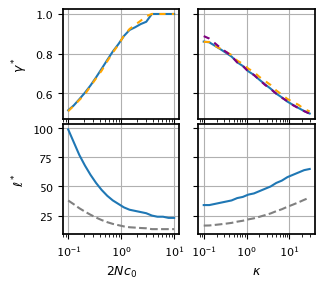

In [13]:
fig, ax_arr = plt.subplots(2, 2, figsize=(4, 3), sharey='row')
ax = np.ravel(ax_arr)
ax[2].set_xscale('log')
ax[2].set_ylabel(r'$\ell^*$')

ax[0].set_ylabel(r'$\gamma^*$')
ax[0].set_xscale('log')

c_arr = np.logspace(-1, 1, num=20)


k = 0.1
l_list = []
g_list = []
g_theo = []
g_theo2 = []
for _c in c_arr:
    c = _c / (2*N)
    lm, lst, _ = lstar(k, c, N=N, lmax=300)
    
    # x = range(lm, 1000)
    # y = [Fitness_nb(gamma_star(l, k, c), l, c, gap, l0, f0, n) for l in x]
    gst = gamma_star(lst, k, c)

    g_list.append(gst)
    l_list.append(lst)
    g_arr = np.linspace(gamma50_nb(lst, gap, l0, n), 1, 100)
    ind = np.argmin(np.abs([2 * N * (Fitness_nb(g+1/(2*lst), lst, c, gap, l0, f0, n) - Fitness_nb(g-1/(2*lst), lst, c, gap, l0, f0, n))  - (1 + k) * (g - 1/4) / (1/4 * (1 - 1/4)) for g in g_arr]))
    g_theo.append(g_arr[ind])
    #ind = np.argmin(np.abs([2 * N * (Fitness_nb(g+1/(2*lst), lst, c, gap, l0, f0, n) - Fitness_nb(g-1/(2*lst), lst, c, gap, l0, f0, n))  - (1 + k) * (g - 1/4) / (1/4 * (1 - 1/4)) for g in g_arr]))
    #g_theo2.append(g_arr[ind])



ax[2].plot(c_arr, l_list)
ax[2].plot(c_arr, l0 / (np.array(g_list) - 1/4), ls='--', color="gray") 
ax[0].plot(c_arr, g_list) 
ax[0].plot(c_arr, g_theo, ls='--', alpha=1, color="orange", dashes=(3, 3)) 
#ax[0].plot(c_arr, g_theo2, ls='--')


ax[3].set_xscale('log')
ax[3].set_ylabel(r'$\ell^*$')

ax[1].set_ylabel(r'$\gamma^*$')
ax[1].set_xscale('log')

k_arr = np.logspace(-1, np.log10(30), num=20)
_c = 1
    
l_list = []
g_list = []
g_theo = []
g_theo2 = []
for k in k_arr:
    c = _c / (2*N)
    lm, lst, _ = lstar(k, c, N=N, lmax=300)
    
    #x = range(lm, 300)
    #y = [Fitness_nb(gamma_star(l, k, c), l, c, gap, l0, f0, n) for l in x]
    gst = gamma_star(lst, k, c)
   
    g_list.append(gst)
    l_list.append(lst)

    g_arr = np.linspace(gamma50_nb(lst, gap, l0, n), 1-1/(2*lst), 100)
    ind = np.argmin(np.abs([2 * N * (Fitness_nb(g+1/(2*lst), lst, c, gap, l0, f0, n) - Fitness_nb(g-1/(2*lst), lst, c, gap, l0, f0, n))  - k * (g - 1/4) / (1/4 * (1 - g)) for g in g_arr]))
    g_theo.append(g_arr[ind])
    ind = np.argmin(np.abs([2 * N * (Fitness_nb(g+1/(2*lst), lst, c, gap, l0, f0, n) - Fitness_nb(g-1/(2*lst), lst, c, gap, l0, f0, n))  - (1 + k) * (g - 1/4) / (1/4 * (1 - 1/4)) for g in g_arr]))
    g_theo2.append(g_arr[ind])
    

ax[3].plot(k_arr, l_list, label=np.round(2*N*c, decimals=1)) 
ax[3].plot(k_arr, l0 / (np.array(g_list) - 1/4), ls='--', color="gray") 
ax[1].plot(k_arr, g_list) 
ax[1].plot(k_arr, g_theo2, ls='--', alpha=1, color="orange", dashes=(3, 3)) 
ax[1].plot(k_arr, g_theo, ls='--', alpha=1, color="purple", dashes=(3, 3)) 
 



ax[3].set_xlabel(r'$\kappa$')
ax[2].set_xlabel(r'$2Nc_0$')

for _ax in ax:
    _ax.label_outer() # Apply label_outer() to each subplot
    _ax.grid(True)


custom_handles = [
    Line2D([0], [0], color="orange", ls='--', label="weak driving", alpha=1),
    Line2D([0], [0], color="green", ls='--', label="strong driving", alpha=1),
]
#fig.legend(handles=custom_handles, loc="center left", ncol=1, bbox_to_anchor=(0.8, 0.76), fontsize=6)


custom_handles = [
    Line2D([0], [0], color="gray", ls='--', label=r"$\frac{\ell_0}{\gamma^*(\ell) - \gamma_0}$"),
]
#fig.legend(handles=custom_handles, loc="center left", ncol=1, bbox_to_anchor=(.8, 0.375))

fig.tight_layout(h_pad=0, w_pad=1)
fig.subplots_adjust(right=0.8)  

#fig.savefig('kappa_c0.pdf')

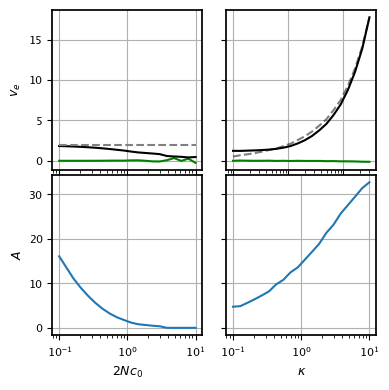

In [14]:
fig, ax_arr = plt.subplots(2, 2, figsize=(4, 4), sharey='row')
ax = np.ravel(ax_arr)

ax[0].set_xscale('log')
ax[1].set_xscale('log')
ax[2].set_xscale('log')
ax[3].set_xscale('log')

ax[0].set_ylabel(r'$v_e$')
ax[2].set_ylabel(r'$A$')

ax[2].set_xlabel(r'$2Nc_0$')
ax[3].set_xlabel(r'$\kappa$')


c_arr = np.logspace(-1, 1, num=20)

k = 0.1
v_e = []
v_tot = []
v_theo = []
A_arr = []

for _c in c_arr:
    c = _c / (2*N)
    lm, lst, _ = lstar(k, c, N=N, lmax=300)
    gst = gamma_star(lst, k, c)

    v_e.append(v_plus_star(lst, k, c, gap, l0, f0, n, N) - v_minus_star(lst, k, c, gap, l0, f0, n, N))
    v_tot.append(v_plus_star(lst, k, c, gap, l0, f0, n, N) + v_minus_star(lst, k, c, gap, l0, f0, n, N))
    A_arr.append(1/3 * lst * (1-gst))
    #v_theo.append(k*(gst - 1/4)/(1/4 * (1-gst)))

ax[0].plot(c_arr, v_e, color="green")
ax[0].plot(c_arr, v_tot, color="black") 
#ax[0].plot(c_arr, v_theo, color="black", ls='--', alpha=0.5) 
ax[2].plot(c_arr, A_arr) 


k_arr = np.logspace(-1, np.log10(30), num=20)

_c = 1
v_e = []
v_tot = []
v_theo = []
A_arr = []

for k in k_arr:
    c = _c / (2*N)
    lm, lst, _ = lstar(k, c, N=N, lmax=300)
    
    gst = gamma_star(lst, k, c)
   
    v_e.append(v_plus_star(lst, k, c, gap, l0, f0, n, N) - v_minus_star(lst, k, c, gap, l0, f0, n, N))
    v_tot.append(v_plus_star(lst, k, c, gap, l0, f0, n, N) + v_minus_star(lst, k, c, gap, l0, f0, n, N))
    A_arr.append(lst * (1-gst))
    v_theo.append(.3*k*(gst - 1/4)/(1/4 * (1-gst)))

ax[1].plot(k_arr, v_e, color="green")
ax[1].plot(k_arr, v_tot, color="black")
ax[1].plot(k_arr, v_theo, color="black", ls='--', alpha=0.5)  
ax[3].plot(c_arr, A_arr) 

ax[0].plot([np.min(c_arr), np.max(c_arr)], [2, 2], color="gray", ls='--')
#ax[1].plot([np.min(k_arr), np.max(k_arr)], [2, 2], color="gray", ls='--') 


for _ax in ax:
    _ax.label_outer() # Apply label_outer() to each subplot
    _ax.grid(True)


# custom_handles = [
#     Line2D([0], [0], color="orange", ls='--', label="weak driving", alpha=0.75),
#     Line2D([0], [0], color="green", ls='--', label="strong driving", alpha=0.75),
# ]
# fig.legend(handles=custom_handles, loc="center left", ncol=1, bbox_to_anchor=(0.8, 0.76), fontsize=6)


# custom_handles = [
#     Line2D([0], [0], color="gray", ls='--', label=r"$\frac{\ell_0}{\gamma^*(\ell) - \gamma_0}$"),
# ]
# fig.legend(handles=custom_handles, loc="center left", ncol=1, bbox_to_anchor=(.8, 0.375))

fig.tight_layout(h_pad=0, w_pad=1)
#fig.subplots_adjust(right=0.8)  

#fig.savefig('kappa_c0.pdf')

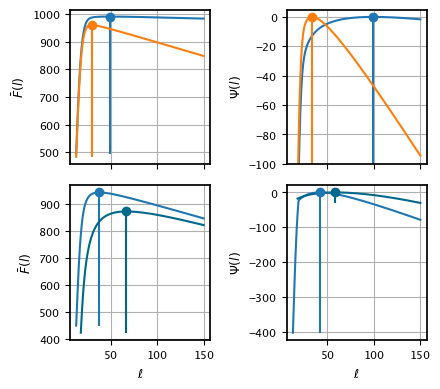

In [15]:
fig, ax_arr = plt.subplots(2, 2, figsize=(4.5, 4), sharex=True)
ax = np.ravel(ax_arr)

# ax[0].set_ylabel(r'$v_e$')
# ax[0].set_xlabel(r'$\ell$')


# ax[1].set_ylabel(r'$v_\mathrm{tot}$')
# ax[1].set_xlabel(r'$\ell$')


ax[0].set_ylabel(r'$\bar{F}(l)$')
#ax[0].set_xlabel(r'$\ell$')

ax[1].set_ylabel(r'$\Psi(l)$')
#ax[1].set_xlabel(r'$\ell$')

ax[2].set_ylabel(r'$\bar{F}(l)$')
ax[2].set_xlabel(r'$\ell$')

ax[3].set_ylabel(r'$\Psi(l)$')
ax[3].set_xlabel(r'$\ell$')


for _c, color in zip([0.1, 1], [colors[0], colors[1]]):
    c = _c/(2*N)
    k = 0.1
 
    lm, lst, flist = lstar(k, c, N=N, lmax=150)
    flist = flist - np.max(flist)
    F_arr = []
    l_arr = np.arange(lm, 151)
    v_e_arr = []
    v_tot_arr = []
    for l in l_arr:
        gst = gamma_star(l, k, c)
        psi = Psi_k_nb(l, k, c, gap, l0, f0, n, N)
        psi -= np.max(psi)
        Q = 0
        for i, g in enumerate(np.arange(0, l+1)/l):
            Q += np.exp(psi[i]) * Fitness_nb(g, l, 0, gap, l0, f0, n)

        F_arr.append(Q / np.sum(np.exp(psi)))
        #v_e = v_plus_star(l, k, c, gap, l0, f0, n, N) - v_minus_star(l, k, c, gap, l0, f0, n, N)
        #v_e_arr.append(v_e)
        #v_tot = v_plus_star(l, k, c, gap, l0, f0, n, N) + v_minus_star(l, k, c, gap, l0, f0, n, N)
        #v_tot_arr.append(v_tot)
    
    ind = np.argmax(2*N*(F_arr- l_arr * c))
    ax[0].plot(l_arr, 2*N*(F_arr - l_arr * c), color=color)
    ax[0].scatter(l_arr[ind],2*N*((F_arr - l_arr * c))[ind], color=color, zorder=3)
    ax[0].vlines(l_arr[ind], np.min(2*N*(F_arr - l_arr * c)), 2*N*(F_arr - l_arr * c)[ind], color=color)
    

    ind = np.argmax(flist)
    ax[1].plot(l_arr, flist, color=color)
    ax[1].scatter(l_arr[ind], flist[ind], color=color, zorder=3)
    ax[1].vlines(l_arr[ind], np.min(flist), flist[ind], color=color)

c = 1/(2*N)
for k, color in zip([1, 10], [colors[0], "#00688b"]):

    lm, lst, flist = lstar(k, c, N=N, lmax=150)
    flist = flist - np.max(flist)
    F_arr = []
    l_arr = np.arange(lm, 151)
    v_e_arr = []
    v_tot_arr = []
    for l in l_arr:
        gst = gamma_star(l, k, c)
        psi = Psi_k_nb(l, k, c, gap, l0, f0, n, N)
        psi -= np.max(psi)
        Q = 0
        for i, g in enumerate(np.arange(0, l+1)/l):
            Q += np.exp(psi[i]) * Fitness_nb(g, l, 0, gap, l0, f0, n)

        F_arr.append(Q / np.sum(np.exp(psi)))
        #v_e = v_plus_star(l, k, c, gap, l0, f0, n, N) - v_minus_star(l, k, c, gap, l0, f0, n, N)
        #v_e_arr.append(v_e)
        #v_tot = v_plus_star(l, k, c, gap, l0, f0, n, N) + v_minus_star(l, k, c, gap, l0, f0, n, N)
        #v_tot_arr.append(v_tot)
    
    ind = np.argmax(2*N*(F_arr- l_arr * c))
    ax[2].plot(l_arr, 2*N*(F_arr - l_arr * c), color=color)
    ax[2].scatter(l_arr[ind],2*N*(F_arr - l_arr * c)[ind], color=color, zorder=3)
    ax[2].vlines(l_arr[ind], np.min(2*N*(F_arr - l_arr * c)), 2*N*(F_arr - l_arr * c)[ind], color=color)
    

    ind = np.argmax(flist)
    ax[3].plot(l_arr, flist, color=color)
    ax[3].scatter(l_arr[ind], flist[ind], color=color, zorder=3)
    ax[3].vlines(l_arr[ind], np.min(flist), flist[ind], color=color)

#ax[0].set_ylim(0.004, 0.005)
ax[0].grid(True)

ax[1].set_ylim(-100, 5)
ax[1].grid(True)

#ax[1].set_ylim(0, 10)
ax[2].grid(True)

#ax[1].set_ylim(0, 10)
ax[3].grid(True)


plt.tight_layout()
#fig.savefig('constraint_ratchet.pdf')

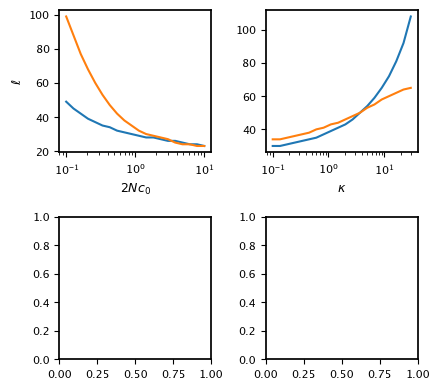

In [16]:
fig, ax_arr = plt.subplots(2, 2, figsize=(4.5, 4))
ax = np.ravel(ax_arr)

ax[0].set_xscale('log')
ax[1].set_xscale('log')

ax[0].set_ylabel(r'$\ell$')
# ax[0].set_xlabel(r'$\ell$')


# ax[1].set_ylabel(r'$v_\mathrm{tot}$')
# ax[1].set_xlabel(r'$\ell$')


#ax[0].set_ylabel(r'$\bar{F}(l)$')
ax[0].set_xlabel(r'$2Nc_0$')

#ax[1].set_ylabel(r'$\Psi(l)$')
ax[1].set_xlabel(r'$\kappa$')

k = 0.1
c_arr = np.logspace(-1, 1, num=20)
F_max = []
psi_max = []
for _c in c_arr:
    c = _c/(2*N)
    
    lm, lst, flist = lstar(k, c, N=N, lmax=150)
    flist = flist - np.max(flist)
    F_arr = []
    l_arr = np.arange(lm, 151)

    for l in l_arr:
        gst = gamma_star(l, k, c)
        psi = Psi_k_nb(l, k, c, gap, l0, f0, n, N)
        psi -= np.max(psi)
        Q = 0
        for i, g in enumerate(np.arange(0, l+1)/l):
            Q += np.exp(psi[i]) * Fitness_nb(g, l, 0, gap, l0, f0, n)

        F_arr.append(Q / np.sum(np.exp(psi)))

    
    ind = np.argmax(F_arr- l_arr * c)
    F_max.append(l_arr[ind])
    ind = np.argmax(flist)
    psi_max.append(l_arr[ind])
    
ax[0].plot(c_arr, F_max)
ax[0].plot(c_arr, psi_max)

F_max = []
psi_max = []

c = 1/(2*N)
for k in k_arr:

    lm, lst, flist = lstar(k, c, N=N, lmax=150)
    flist = flist - np.max(flist)
    F_arr = []
    l_arr = np.arange(lm, 151)

    for l in l_arr:
        gst = gamma_star(l, k, c)
        psi = Psi_k_nb(l, k, c, gap, l0, f0, n, N)
        psi -= np.max(psi)
        Q = 0
        for i, g in enumerate(np.arange(0, l+1)/l):
            Q += np.exp(psi[i]) * Fitness_nb(g, l, 0, gap, l0, f0, n)

        F_arr.append(Q / np.sum(np.exp(psi)))

    
    ind = np.argmax(F_arr- l_arr * c)
    F_max.append(l_arr[ind])
    ind = np.argmax(flist)
    psi_max.append(l_arr[ind])


ax[1].plot(k_arr, F_max)
ax[1].plot(k_arr, psi_max)


plt.tight_layout()
#fig.savefig('constraint_ratchet.pdf')

In [17]:
def g_rate(s, N):
    return N * kimura(s, N)

# ———————— Inverse substitution probability ————————
def ginv(u, N=N):
    """
    Solve for x such that g_rate_nb(x, N) == u.
    """
    sol = fsolve(lambda x: g_rate(x, N)/N - u/N, 1/N)
    return float(sol[0])

# ———————— Effective selective coefficients ————————
def seffplus(l, kappa, c, gap, l0, f0, n, N):
    """Effective s for length increase at ℓ."""
    return ginv(v_plus_star(l, kappa, c, gap, l0, f0, n, N), N)

def seffminus(l, kappa, c, gap, l0, f0, n, N):
    """Effective s for length decrease at ℓ."""
    return ginv(v_minus_star(l, kappa, c, gap, l0, f0, n, N), N)

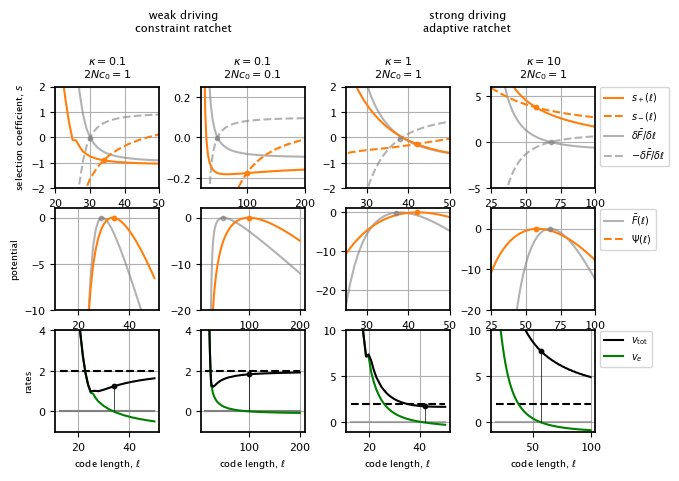

In [18]:
fig, ax_arr = plt.subplots(3, 4, figsize=(8, 5))#, sharex='col')#, sharey='row')
ax = np.ravel(ax_arr)

#ax[0].set_ylabel(r'$\bar{F}(l)$')
#ax[0].set_xlabel(r'$\ell$')


#ax[1].set_ylabel(r'$\Psi(l)$')
#ax[1].set_xlabel(r'$\ell$')


k = 0.1
for j, (_c, color, lmax) in enumerate(zip([1, 0.1], [colors[0], colors[1]], [50, 200])):
    c = _c/(2*N)
    lm, lst, flist = lstar(k, c, N=N, lmax=lmax)
    l_arr = np.arange(lm, lmax+1)
    flist = flist - np.max(flist)
    sp = []
    sm = []
    Q_arr = []
    v_e = []
    v_tot = []

    
    for l in l_arr:
        gst = gamma_star(l, k, c)
        F_arr.append(Q / np.sum(np.exp(psi)))
        gst = gamma_star(l, k, c)
        psi = Psi_k_nb(l, k, c, gap, l0, f0, n, N)
        psi -= np.max(psi)
        Q_norm = np.sum(np.exp(psi))
        Q = 0
        for i, g in enumerate(np.arange(0, l+1)/l):
            Q += np.exp(psi[i]) * Fitness_nb(g, l, c, gap, l0, f0, n)/Q_norm
        Q_arr.append(Q)
        sm.append(2*N*seffminus(l, k, c, gap, l0, f0, n, N))
        sp.append(2*N*seffplus(l, k, c, gap, l0, f0, n, N))
        v_tot.append(v_plus_star(l, k, c, gap, l0, f0, n, N) + v_minus_star(l, k, c, gap, l0, f0, n, N))
        v_e.append(v_plus_star(l, k, c, gap, l0, f0, n, N) - v_minus_star(l, k, c, gap, l0, f0, n, N))
    
    y1 = np.array([2*N*(Q_arr[i] - Q_arr[i-1]) for i in np.arange(1, len(Q_arr))])
    y2 = np.array([-2*N*(Q_arr[i] - Q_arr[i-1]) for i in np.arange(1, len(Q_arr))])
    
    ax[j].plot(l_arr[1:], y1, color="gray", alpha=0.6)
    ax[j].plot(l_arr[1:], y2, color="gray", alpha=0.6, ls='--')
    ax[4+j].plot(l_arr, 2*N*(np.array(Q_arr) - np.max(np.array(Q_arr))), color="gray", alpha=0.6)

    ind = np.argmin(np.abs(y2 - y1))
    ax[j].scatter(l_arr[1:][ind], y2[ind], color="gray", alpha=0.6, zorder=3, s=10)
    ax[j+4].scatter(l_arr[ind], 2*N*(np.array(Q_arr) - np.max(np.array(Q_arr)))[ind], color="gray", zorder=3, s=10, alpha=0.6)

    ax[j].plot(l_arr, sp, color=colors[1])
    ax[j].plot(l_arr, sm, color=colors[1], ls = '--')
    ax[4+j].plot(l_arr, flist, color=colors[1])

    ind = np.argmin(np.abs(np.array(sp) - np.array(sm)))
    ax[j].scatter(l_arr[ind], sp[ind], color=colors[1], zorder=3, s=10)
    ax[j+4].scatter(l_arr[ind], flist[ind], color=colors[1], zorder=3, s=10)

    ax[j+8].plot(l_arr, np.ones(len(l_arr))*2, color='black', ls='--')
    ax[j+8].plot(l_arr, np.zeros(len(l_arr)), color='gray')
    ax[j+8].plot(l_arr, v_e, color='green')
    ax[j+8].plot(l_arr, v_tot, color='black')
    ax[j+8].scatter(l_arr[ind], v_tot[ind], color="black", zorder=3, s=10)
    ax[j+8].vlines(l_arr[ind], ymax=v_tot[ind], ymin=0, color="black", zorder=3, linewidth=0.5)

c = 1/(2*N)
for j, (k, color, lmax) in enumerate(zip([1, 10], ["gray", colors[1]], [50, 100])):
    
    lm, lst, flist = lstar(k, c, N=N, lmax=lmax)
    l_arr = np.arange(lm, lmax+1)
    flist = flist - np.max(flist)
    sp = []
    sm = []
    Q_arr = []
    v_e = []
    v_tot = []
    for l in l_arr:
        gst = gamma_star(l, k, c)
        psi = Psi_k_nb(l, k, c, gap, l0, f0, n, N)
        psi -= np.max(psi)
        Q_norm = np.sum(np.exp(psi))
        Q = 0
        for i, g in enumerate(np.arange(0, l+1)/l):
            Q += np.exp(psi[i]) * Fitness_nb(g, l, c, gap, l0, f0, n)/Q_norm
        Q_arr.append(Q)
        sm.append(2*N*seffminus(l, k, c, gap, l0, f0, n, N))
        sp.append(2*N*seffplus(l, k, c, gap, l0, f0, n, N))
        v_tot.append(v_plus_star(l, k, c, gap, l0, f0, n, N) + v_minus_star(l, k, c, gap, l0, f0, n, N))
        v_e.append(v_plus_star(l, k, c, gap, l0, f0, n, N) - v_minus_star(l, k, c, gap, l0, f0, n, N))
    
    y1 = np.array([2*N*(Q_arr[i] - Q_arr[i-1]) for i in np.arange(1, len(Q_arr))])
    y2 = np.array([-2*N*(Q_arr[i] - Q_arr[i-1]) for i in np.arange(1, len(Q_arr))])
    
    ax[j+2].plot(l_arr[1:], y1, color="gray", alpha=0.6)
    ax[j+2].plot(l_arr[1:], y2, color="gray", ls='--', alpha=0.6)
    ax[6+j].plot(l_arr, 2*N*(np.array(Q_arr) - np.max(np.array(Q_arr))), color="gray", alpha=0.6)
    

    ind = np.argmin(np.abs(y2 - y1))
    ax[j+2].scatter(l_arr[1:][ind], y2[ind], color="gray", alpha=0.6, zorder=3, s=10)

    ax[j+2].plot(l_arr, sp, color=colors[1])
    ax[j+2].plot(l_arr, sm, color=colors[1], ls='--')
    ax[6+j].plot(l_arr, flist, color=colors[1])
    ax[6+j].set_xlim(25, lmax)
    ax[2+j].set_xlim(25, lmax)
    ax[j+6].scatter(l_arr[ind], 2*N*(np.array(Q_arr) - np.max(np.array(Q_arr)))[ind], color="gray", zorder=3, s=10, alpha=0.6)


    ind = np.argmin(np.abs(np.array(sp) - np.array(sm)))
    ax[j+2].scatter(l_arr[ind], sp[ind], color=colors[1], zorder=3, s=10)
    ax[j+6].scatter(l_arr[ind], flist[ind], color=colors[1], zorder=3, s=10)


    ax[j+10].plot(l_arr, np.ones(len(l_arr))*2, color='black', ls='--')
    ax[j+10].plot(l_arr, np.zeros(len(l_arr)), color='gray', alpha=0.6)
    ax[j+10].plot(l_arr, v_e, color='green')
    ax[j+10].plot(l_arr, v_tot, color='black')
    ax[j+10].scatter(l_arr[ind], v_tot[ind], color="black", zorder=3, s=10)
    ax[j+10].vlines(l_arr[ind], ymax=v_tot[ind], ymin=0, color="black", zorder=3, linewidth=0.5)
    


    

#ax[0].set_ylim(0.004, 0.005)
for _ax in ax:
    _ax.grid(True)



ax[0].set_title(r'$\kappa=0.1$' + '\n' + r'$2Nc_0=1$', fontsize=8)
#x[0].set_ylim(-10, 10)
ax[1].set_title(r'$\kappa=0.1$' + '\n' +  r'$2Nc_0=0.1$', fontsize=8)
ax[2].set_title(r'$\kappa=1$' + '\n' +  r'$2Nc_0=1$', fontsize=8)
ax[3].set_title(r'$\kappa=10$' + '\n' +  r'$2Nc_0=1$', fontsize=8)

#ax[1].set_ylim(-100, 5)
ax[1].grid(True)

ax[8].set_xlabel("code length, " + r'$\ell$', fontsize=7)
ax[9].set_xlabel("code length, " + r'$\ell$', fontsize=7)
ax[10].set_xlabel("code length, " + r'$\ell$', fontsize=7)
ax[11].set_xlabel("code length, " + r'$\ell$', fontsize=7)

ax[0].set_ylabel("selection coefficient, " + r'$s$', fontsize=7)
ax[4].set_ylabel("potential", fontsize=7)
ax[8].set_ylabel("rates", fontsize=7)


ax[0].set_xlim(20, 50)
ax[1].set_xlim(20, 200)



#ax[1].set_ylim(-20, 1)
ax[1].set_ylim(-0.25, 0.25)
ax[0].set_ylim(-2, 2)
ax[2].set_ylim(-2, 2)
ax[3].set_ylim(-5, 6)

ax[4].set_ylim(-10, 1)
ax[5].set_ylim(-20, 2)
ax[6].set_ylim(-25, 1)
ax[7].set_ylim(-20, 5)

ax[8].set_ylim(-1, 4)
ax[9].set_ylim(-1, 4)
ax[10].set_ylim(-1, 10)
ax[11].set_ylim(-1, 10)

fig.text(0.285, 0.93, "weak driving\nconstraint ratchet", horizontalalignment='center', verticalalignment='center', fontsize=8)
fig.text(0.64, 0.93, "strong driving\nadaptive ratchet", horizontalalignment='center', verticalalignment='center', fontsize=8) 


custom_handles = [
    Line2D([0], [0], color=colors[1], label=r"$s_+(\ell)$", alpha=1),
    Line2D([0], [0], color=colors[1], label=r"$s_-(\ell)$", ls='--'),
    Line2D([0], [0], color="gray", label=r"$\delta \bar{F}/\delta \ell$", alpha=0.6),
    Line2D([0], [0], color="gray", label=r"$-\delta \bar{F}/\delta \ell$", ls='--', alpha=0.6)
]
fig.legend(handles=custom_handles, loc="center left", ncol=1, bbox_to_anchor=(0.8, 0.72), fontsize=7)
fig.subplots_adjust(top=0.79, right=0.8)  


custom_handles = [
    Line2D([0], [0], color="gray", label=r"$\bar{F}(\ell)$", alpha=0.6),
    Line2D([0], [0], color=colors[1], label=r"$\Psi(\ell)$", ls='--'),
]
fig.legend(handles=custom_handles, loc="center left", ncol=1, bbox_to_anchor=(0.8, 0.515), fontsize=7)


custom_handles = [
    Line2D([0], [0], color="black", label=r"$v_\mathrm{tot}$", alpha=1),
    Line2D([0], [0], color="green", label=r"$v_e$"),
]
fig.legend(handles=custom_handles, loc="center left", ncol=1, bbox_to_anchor=(0.8, 0.275), fontsize=7)
fig.subplots_adjust(top=0.8, right=0.8, wspace=0.4,) #
#plt.tight_layout()
#fig.savefig('ratchet_potentials.pdf')

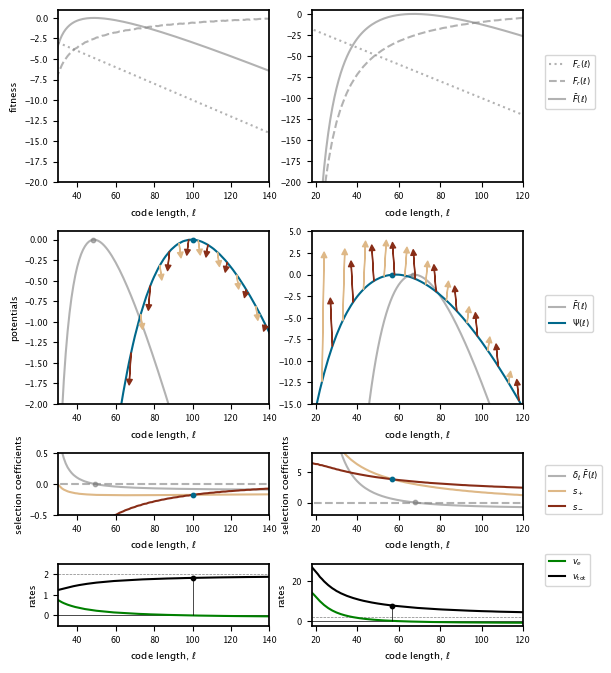

In [89]:
fig = plt.figure(figsize=(6, 8))
gs = gridspec.GridSpec(6, 4, figure=fig)

ax01 = fig.add_subplot(gs[0:2, 0:2])  # Top-left subplot
ax02 = fig.add_subplot(gs[0:2, 2:4])  # Top-left subplot
ax1 = fig.add_subplot(gs[2:4, 0:2])  # Top-left subplot
ax2 = fig.add_subplot(gs[2:4, 2:4])  # Top-left subplot
ax3 = fig.add_subplot(gs[4, 0:2])  # Top-right subplot
ax4 = fig.add_subplot(gs[5, 0:2])

ax5 = fig.add_subplot(gs[4, 2:]) # Top-right subplot
ax6 = fig.add_subplot(gs[5, 2:])


lmax = 150
k = 0.1
c = 0.1/(2*N)
lm, lst, flist = lstar(k, c, N=N, lmax=lmax)
l_arr = np.arange(lm, lmax+1)
flist = flist - np.max(flist)
sp = []
sm = []
Q_arr = []
v_e = []
v_tot = []
F_max = []


for l in l_arr:
    gst = gamma_star(l, k, c)
    F_arr.append(Q / np.sum(np.exp(psi)))
    gst = gamma_star(l, k, c)
    F_max.append(2*N*Fitness_nb(gst, l, 0, gap, l0, f0, n))
    psi = Psi_k_nb(l, k, c, gap, l0, f0, n, N)
    psi -= np.max(psi)
    Q_norm = np.sum(np.exp(psi))
    Q = 0
    for i, g in enumerate(np.arange(0, l+1)/l):
        Q += np.exp(psi[i]) * Fitness_nb(g, l, c, gap, l0, f0, n)/Q_norm
    Q_arr.append(Q)
    sm.append(2*N*seffminus(l, k, c, gap, l0, f0, n, N))
    sp.append(2*N*seffplus(l, k, c, gap, l0, f0, n, N))
    v_tot.append(v_plus_star(l, k, c, gap, l0, f0, n, N) + v_minus_star(l, k, c, gap, l0, f0, n, N))
    v_e.append(v_plus_star(l, k, c, gap, l0, f0, n, N) - v_minus_star(l, k, c, gap, l0, f0, n, N))


y1 = np.array([2*N*(Q_arr[i] - Q_arr[i-1]) for i in np.arange(1, len(Q_arr))])
y2 = np.array([-2*N*(Q_arr[i] - Q_arr[i-1]) for i in np.arange(1, len(Q_arr))])

ind = np.argmin(np.abs(y2 - y1))

# Top left plot
ax01.plot(l_arr[1:], -2*N*c * l_arr[1:], color="gray", alpha=0.6, ls='dotted', label=r"$F_c(\ell)$")
ax01.plot(l_arr[1:], F_max[1:] - np.max(F_max[1:]), color="gray", alpha=0.6, ls='--', label=r"$F_r(\ell)$")
ax01.plot(l_arr, 2*N*(np.array(Q_arr) - np.max(np.array(Q_arr))), color="gray", alpha=0.6, label=r"$\bar{F}(\ell)$")

# second row left plot
ax1.plot(l_arr, 2*N*(np.array(Q_arr) - np.max(np.array(Q_arr))), color="gray", alpha=0.6, label=r"$\bar{F}(\ell)$")
ax1.scatter(l_arr[ind], 2*N*(np.array(Q_arr) - np.max(np.array(Q_arr)))[ind], color="gray", zorder=3, s=10, alpha=0.6)
ax1.plot(l_arr, flist, color="#00688b", label=r"$\Psi(\ell)$")


ax3.plot(l_arr[1:], y1, color="gray", alpha=0.6, label=r'$\delta_\ell\ \bar{F}(\ell)$')
#ax3.plot(l_arr[1:], y2, color="gray", alpha=0.6, ls='--')
ax3.plot(l_arr[1:], np.zeros(len(l_arr[1:])), color="gray", alpha=0.6, ls='--')


ind = np.argmin(np.abs(y2 - y1))
ax3.scatter(l_arr[1:][ind], y2[ind], color="gray", alpha=0.6, zorder=3, s=10)

ax3.plot(l_arr, sp, color="#deb887", label=r'$s_+$')
ax3.plot(l_arr, sm, color="#882D17", label=r'$s_-$')


ind = np.argmin(np.abs(np.array(sm) - np.array(sp)))
ax4.plot([np.min(l_arr), np.max(l_arr)], [2, 2], color='gray', lw=0.5, ls='--')
ax4.plot([np.min(l_arr), np.max(l_arr)], [0, 0], color='black', lw=0.5)
ax4.plot(l_arr, v_e, color='green', label=r'$v_e$')
ax4.plot(l_arr, v_tot, color='black', label=r'$v_\mathrm{tot}$')

ax4.scatter([l_arr[ind]], [v_tot[ind]], color='black', zorder=3, s=10)
ax1.scatter(l_arr[ind], flist[ind], color="#00688b", zorder=3, s=10)
ax3.scatter(l_arr[ind], sp[ind], color="#00688b", zorder=3, s=10)
ax4.vlines(l_arr[ind], ymax=v_tot[ind], ymin=0, color='black', zorder=3, lw=0.5)

ax1.set_xlim(lm, 150)
ax3.set_xlim(lm, 150)
ax4.set_xlim(lm, 150)

for i in np.arange(len(sp))[::10]:
    ax1.annotate(text=None, xycoords='data', xytext=(l_arr[i], flist[i]), xy=(1+l_arr[i], sp[i]+flist[i]), arrowprops=dict(width=0.1, color='#deb887', headwidth=4, headlength=4))
    #ax1.vlines(x=1+l_arr[i], ymax=sp[i]+flist[i], ymin=flist[i], color='#deb887', ls='--')
    ax1.annotate(text=None, xycoords='data', xytext=(l_arr[i+5], flist[i+5]), xy=(-1+l_arr[i+5], sm[i+5]+flist[i+5]), arrowprops=dict(width=0.1, color='#882D17', headwidth=4, headlength=4))
    #ax1.vlines(x=l_arr[i+5]-1, ymax=sm[i+5]+flist[i+5], ymin=flist[i+5], color='#882D17', ls='--')



k = 10
c = 1/(2*N)
lm, lst, flist = lstar(k, c, N=N, lmax=lmax)
l_arr = np.arange(lm, lmax+1)
flist = flist - np.max(flist)
sp = []
sm = []
Q_arr = []
v_e = []
v_tot = []
F_max = []


for l in l_arr:
    gst = gamma_star(l, k, c)
    F_arr.append(Q / np.sum(np.exp(psi)))
    gst = gamma_star(l, k, c)
    F_max.append(2*N*Fitness_nb(gst, l, 0, gap, l0, f0, n))
    psi = Psi_k_nb(l, k, c, gap, l0, f0, n, N)
    psi -= np.max(psi)
    Q_norm = np.sum(np.exp(psi))
    Q = 0
    for i, g in enumerate(np.arange(0, l+1)/l):
        Q += np.exp(psi[i]) * Fitness_nb(g, l, c, gap, l0, f0, n)/Q_norm

    Q_arr.append(Q)
    sm.append(2*N*seffminus(l, k, c, gap, l0, f0, n, N))
    sp.append(2*N*seffplus(l, k, c, gap, l0, f0, n, N))
    v_tot.append(v_plus_star(l, k, c, gap, l0, f0, n, N) + v_minus_star(l, k, c, gap, l0, f0, n, N))
    v_e.append(v_plus_star(l, k, c, gap, l0, f0, n, N) - v_minus_star(l, k, c, gap, l0, f0, n, N))

y1 = np.array([2*N*(Q_arr[i] - Q_arr[i-1]) for i in np.arange(1, len(Q_arr))])
y2 = np.array([-2*N*(Q_arr[i] - Q_arr[i-1]) for i in np.arange(1, len(Q_arr))])


ind = np.argmin(np.abs(y2 - y1))

# Top right plot
ax02.plot(l_arr[1:], -2*N*c * l_arr[1:], color="gray", alpha=0.6, ls='dotted')
ax02.plot(l_arr[1:], F_max[1:] - np.max(F_max[1:]), color="gray", alpha=0.6, ls='--')
ax02.plot(l_arr, 2*N*(np.array(Q_arr) - np.max(np.array(Q_arr))), color="gray", alpha=0.6)

# Second row right
ax2.plot(l_arr, 2*N*(np.array(Q_arr) - np.max(np.array(Q_arr))), color="gray", alpha=0.6)
ax2.scatter(l_arr[ind], 2*N*(np.array(Q_arr) - np.max(np.array(Q_arr)))[ind], color="gray", zorder=3, s=10, alpha=0.6)
ax2.plot(l_arr, flist, color="#00688b")

ax5.plot(l_arr[1:], y1, color="gray", alpha=0.6)
#ax5.plot(l_arr[1:], y2, color="gray", alpha=0.6, ls='--')
ax5.plot(l_arr[1:], np.zeros(len(l_arr[1:])), color="gray", alpha=0.6, ls='--')


ax5.scatter(l_arr[1:][ind], y2[ind], color="gray", alpha=0.6, zorder=3, s=10)

ind = np.argmin(np.abs(np.array(sp) - np.array(sm)))
ax5.plot(l_arr, sp, color='#deb887')
ax5.plot(l_arr, sm, color="#882D17")
ax5.scatter(l_arr[ind], sp[ind], color="#00688b", zorder=3, s=10)
ax2.scatter(l_arr[ind], flist[ind], color="#00688b", zorder=3, s=10)



ax6.plot([np.min(l_arr), np.max(l_arr)], [2, 2], color='gray', lw=0.5, ls='--')
ax6.plot([np.min(l_arr), np.max(l_arr)], [0, 0], color='black', lw=0.5)
ax6.plot(l_arr, v_e, color='green')
ax6.plot(l_arr, v_tot, color='black')
ax6.scatter([l_arr[ind]], [v_tot[ind]], color='black', zorder=3, s=10)
ax6.vlines(l_arr[ind], ymax=v_tot[ind], ymin=0, color='black', zorder=3, lw=0.5)

for i in np.arange(len(sp)-20)[5:][::10]:
    ax2.annotate(text=None, xycoords='data', xytext=(l_arr[i], flist[i]), xy=(1+l_arr[i], sp[i]+flist[i]), arrowprops=dict(width=0.1, color='#deb887', headwidth=4, headlength=4))
    #ax2.vlines(x=1+l_arr[i], ymax=sp[i]+flist[i], ymin=flist[i], color='#deb887', ls='--')
    ax2.annotate(text=None, xycoords='data', xytext=(l_arr[i+5], flist[i+5]), xy=(-1+l_arr[i+5], sm[i+5]+flist[i+5]), arrowprops=dict(width=0.1, color='#882D17', headwidth=4, headlength=4))
    #ax2.vlines(x=l_arr[i+5]-1, ymax=sm[i+5]+flist[i+5], ymin=flist[i+5], color='#882D17', ls='--')




ax01.set_ylim(-20, 1)
ax01.set_xlim(30, 140)
#ax01.set_xlim(30, 140)
ax02.set_ylim(-200, 5)
ax02.set_xlim(lm, 120)

ax1.set_ylim(-2, .1)
ax2.set_ylim(-15, 5)
ax3.set_ylim(-0.5, 0.5)
ax4.set_ylim(-0.5, 2.5)
ax5.set_ylim(-2, 8)

ax1.set_xlim(30, 140)
ax3.set_xlim(30, 140)
ax4.set_xlim(30, 140)


ax2.set_xlim(lm, 120)
ax5.set_xlim(lm, 120)
ax6.set_xlim(lm, 120)


ax01.set_xlabel('code length, ' + r'$\ell$', fontsize=7)
ax02.set_xlabel('code length, ' + r'$\ell$', fontsize=7)
ax1.set_xlabel('code length, ' + r'$\ell$', fontsize=7)
ax2.set_xlabel('code length, ' + r'$\ell$', fontsize=7)
ax3.set_xlabel('code length, ' + r'$\ell$', fontsize=7)
ax4.set_xlabel('code length, ' + r'$\ell$', fontsize=7)
ax5.set_xlabel('code length, ' + r'$\ell$', fontsize=7)
ax6.set_xlabel('code length, ' + r'$\ell$', fontsize=7)



ax01.set_ylabel('fitness', fontsize=7)
ax1.set_ylabel('potentials', fontsize=7)
#ax2.set_ylabel('potentials')
ax4.set_ylabel('rates', fontsize=7)
ax3.set_ylabel('selection coefficients', fontsize=7)
ax6.set_ylabel('rates', fontsize=7)
ax5.set_ylabel('selection coefficients', fontsize=7)

ax01.tick_params(axis='both', which='major', labelsize=6)
ax01.tick_params(axis='both', which='minor', labelsize=6)

ax02.tick_params(axis='both', which='major', labelsize=6)
ax02.tick_params(axis='both', which='minor', labelsize=6)

ax1.tick_params(axis='both', which='major', labelsize=6)
ax1.tick_params(axis='both', which='minor', labelsize=6)

ax2.tick_params(axis='both', which='major', labelsize=6)
ax2.tick_params(axis='both', which='minor', labelsize=6)

ax3.tick_params(axis='both', which='major', labelsize=6)
ax3.tick_params(axis='both', which='minor', labelsize=6)

ax4.tick_params(axis='both', which='major', labelsize=6)
ax4.tick_params(axis='both', which='minor', labelsize=6)

ax5.tick_params(axis='both', which='major', labelsize=6)
ax5.tick_params(axis='both', which='minor', labelsize=6)

ax6.tick_params(axis='both', which='major', labelsize=6)
ax6.tick_params(axis='both', which='minor', labelsize=6)

# Labels
handles1, labels1 = ax01.get_legend_handles_labels()
fig.legend(handles1, labels1, loc='center left', bbox_to_anchor=(0.93, 0.79),
           fontsize=6)

handles2, labels2 = ax1.get_legend_handles_labels()
fig.legend(handles2, labels2, loc='center left', bbox_to_anchor=(0.93, 0.50),
           fontsize=6)

handles3, labels3 = ax3.get_legend_handles_labels()
fig.legend(handles3, labels3, loc='center left', bbox_to_anchor=(0.93, 0.28),
           fontsize=6)

handles4, labels4 = ax4.get_legend_handles_labels()
fig.legend(handles4, labels4, loc='center left', bbox_to_anchor=(0.93, 0.18),
           fontsize=6)

fig.subplots_adjust(wspace=0.5, hspace=0.8) #

fig.savefig('ratchet_figure_2.pdf')

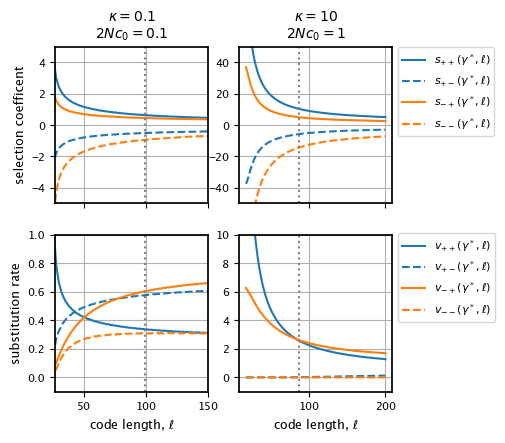

In [1361]:
fig, ax_arr  = plt.subplots(2, 2, figsize=(5, 5), sharex='col')
ax = np.ravel(ax_arr)

k = 0.1
for j, (_c, color, lmax) in enumerate(zip([.1], [colors[0], colors[1]], [200, 50])):
    c = _c/(2*N)
    lm, lst, flist = lstar(k, c, N=N, lmax=lmax)
    l_arr = np.arange(lm, lmax+1)
    spp_arr = []
    vpp_arr = []
    spm_arr = []
    vpm_arr = []
    smm_arr = []
    vmm_arr = []
    smp_arr = []
    vmp_arr = []
    for l in l_arr:

        gst = gamma_star(l, k, c, gap, l0, f0, n, N)
        spp_arr.append(2*N*s_pp(gst, l, c, gap, l0, f0, n, N))
        vpp_arr.append(v_pp(gst, l, c, gap, l0, f0, n, N))

        spm_arr.append(2*N*s_pm(gst, l, c, gap, l0, f0, n, N))
        vpm_arr.append(v_pm(gst, l, c, gap, l0, f0, n, N))

        smm_arr.append(2*N*s_mm(gst, l, c, gap, l0, f0, n, N))
        vmm_arr.append(v_mm(gst, l, c, gap, l0, f0, n, N))

        smp_arr.append(2*N*s_mp(gst, l, c, gap, l0, f0, n, N))
        vmp_arr.append(v_mp(gst, l, c, gap, l0, f0, n, N))

    ax[0].plot(l_arr, spp_arr, color=colors[0], ls='-')
    ax[0].plot(l_arr, spm_arr, color=colors[0], ls='--')
    ax[0].plot(l_arr, smp_arr, color=colors[1], ls='-')
    ax[0].plot(l_arr, smm_arr, color=colors[1], ls='--')

    ax[2].plot(l_arr, vpp_arr, color=colors[0], ls='-')
    ax[2].plot(l_arr, vpm_arr, color=colors[0], ls='--')
    ax[2].plot(l_arr, vmp_arr, color=colors[1], ls='-')
    ax[2].plot(l_arr, vmm_arr, color=colors[1], ls='--')

    ax[0].axvline(lst, color='gray', ls=':')
    ax[2].axvline(lst, color='gray', ls=':')



c = 1/(2*N)
for j, (k, color, lmax) in enumerate(zip([10], [colors[0], colors[1]], [200, 50])):
    c = _c/(2*N)
    lm, lst, flist = lstar(k, c, N=N, lmax=lmax)
    l_arr = np.arange(lm, lmax+1)
    spp_arr = []
    vpp_arr = []
    spm_arr = []
    vpm_arr = []
    smm_arr = []
    vmm_arr = []
    smp_arr = []
    vmp_arr = []
    for l in l_arr:

        gst = gamma_star(l, k, c, gap, l0, f0, n, N)
        spp_arr.append(2*N*s_pp(gst, l, c, gap, l0, f0, n, N))
        vpp_arr.append(v_pp(gst, l, c, gap, l0, f0, n, N))

        spm_arr.append(2*N*s_pm(gst, l, c, gap, l0, f0, n, N))
        vpm_arr.append(v_pm(gst, l, c, gap, l0, f0, n, N))

        smm_arr.append(2*N*s_mm(gst, l, c, gap, l0, f0, n, N))
        vmm_arr.append(v_mm(gst, l, c, gap, l0, f0, n, N))

        smp_arr.append(2*N*s_mp(gst, l, c, gap, l0, f0, n, N))
        vmp_arr.append(v_mp(gst, l, c, gap, l0, f0, n, N))

    ax[1].plot(l_arr, spp_arr, color=colors[0], ls='-')
    ax[1].plot(l_arr, spm_arr, color=colors[0], ls='--')
    ax[1].plot(l_arr, smp_arr, color=colors[1], ls='-')
    ax[1].plot(l_arr, smm_arr, color=colors[1], ls='--')

    ax[3].plot(l_arr, vpp_arr, color=colors[0], ls='-')
    ax[3].plot(l_arr, vpm_arr, color=colors[0], ls='--')
    ax[3].plot(l_arr, vmp_arr, color=colors[1], ls='-')
    ax[3].plot(l_arr, vmm_arr, color=colors[1], ls='--')

    ax[1].axvline(lst, color='gray', ls=':')
    ax[3].axvline(lst, color='gray', ls=':')


ax[0].set_ylim(-5, 5)
ax[0].set_xlim(27, 150)
ax[0].set_ylabel('selection coefficent')
ax[0].set_title(r'$\kappa = 0.1$' + '\n' + r'$2Nc_0=0.1$')

ax[1].set_ylim(-50, 50)
ax[1].set_title(r'$\kappa = 10$' + '\n' + r'$2Nc_0=1$')

ax[2].set_ylabel('substitution rate')
ax[2].set_ylim(-0.1,1.0)
ax[2].set_xlabel('code length, ' + r'$\ell$')

ax[3].set_ylim(-1, 10)
ax[3].set_xlabel('code length, ' + r'$\ell$')


custom_handles = [
    Line2D([0], [0], color=colors[0], label=r"$s_{++}(\gamma^*, \ell)$", alpha=1),
    Line2D([0], [0], color=colors[0], label=r"$s_{+-}(\gamma^*, \ell)$", ls='--'),
    Line2D([0], [0], color=colors[1], label=r"$s_{-+}(\gamma^*, \ell)$", ),
    Line2D([0], [0], color=colors[1], label=r"$s_{--}(\gamma^*, \ell)$", ls='--')
]
fig.legend(handles=custom_handles, loc="upper left", ncol=1, bbox_to_anchor=(0.8, 0.81), fontsize=8)
fig.subplots_adjust(top=0.79, right=0.8)  


custom_handles = [
    Line2D([0], [0], color=colors[0], label=r"$v_{++}(\gamma^*, \ell)$", alpha=1),
    Line2D([0], [0], color=colors[0], label=r"$v_{+-}(\gamma^*, \ell)$", ls='--'),
    Line2D([0], [0], color=colors[1], label=r"$v_{-+}(\gamma^*, \ell)$", ),
    Line2D([0], [0], color=colors[1], label=r"$v_{--}(\gamma^*, \ell)$", ls='--')
]
fig.legend(handles=custom_handles, loc="center left", ncol=1, bbox_to_anchor=(0.8, 0.338), fontsize=8)
fig.subplots_adjust(top=0.8, right=0.8) 

for _ax in ax:
    _ax.grid(True)
#plt.tight_layout()
fig.savefig('SI_s_v_ratchets.pdf')

In [996]:
def g_rate(s, N):
    return N * kimura(s, N)

# ———————— Inverse substitution probability ————————
def ginv(u, N=N):
    """
    Solve for x such that g_rate_nb(x, N) == u.
    """
    sol = fsolve(lambda x: g_rate(x, N)/N - u/N, 1/N)
    return float(sol[0])

# ———————— Effective selective coefficients ————————
def seffplus_u(g, l, k, c, gap, l0, f0, n, N):
    """Effective s for length increase at ℓ."""
    return ginv(up_nb(g, l, k, c, gap, l0, f0, n, N)/(gamma0_nb(n)/(1-gamma0_nb(n)) * (1-g)) -k, N)

def seffminus_u(g, l, k, c, gap, l0, f0, n, N):
    """Effective s for length increase at ℓ."""
    return ginv(um_nb(g, l, k, c, gap, l0, f0, n, N)/g - k, N)

In [828]:
def um(gamma, l, kappa, c, gap, l0, f0, n, N):
    if gamma <= 0.0: 
        return 0.0
    df = (Fitness_nb(gamma - 1/l, l, c, gap, l0, f0, n)
        - Fitness_nb(gamma, l, c, gap, l0, f0, n))
    return gamma * (g_rate_nb(df, N) + kappa)

In [ ]:
 (Fitness_nb(g - 1/l, l, c, gap, l0, f0, n)- Fitness_nb(g, l, c, gap, l0, f0, n))

In [ ]:
 Fitness_nb(g - 1/l, l, c, gap, l0, f0, n) - Fitness_nb(g, l, c, gap, l0, f0, n)

0.0

In [ ]:
g=0.5
l=50
s = Fitness_nb(g - 1/l, l, c, gap, l0, f0, n) - Fitness_nb(g, l, c, gap, l0, f0, n) 

In [829]:
um(g, l, k, c, gap, l0, f0, n, N)/g

10.0

In [832]:
g_rate_nb(s, N)

3.66974108670959e-52

In [834]:
3.66974108670959e-52 + 10

10.0

/var/folders/67/2rd1gct91876bvjs_7ny9rcw0000gn/T/ipykernel_33270/1997363733.py:9: RuntimeWarning: The number of calls to function has reached maxfev = 400.
  sol = fsolve(lambda x: g_rate(x, N)/N - u/N, 1/N)
/var/folders/67/2rd1gct91876bvjs_7ny9rcw0000gn/T/ipykernel_33270/1997363733.py:9: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  sol = fsolve(lambda x: g_rate(x, N)/N - u/N, 1/N)


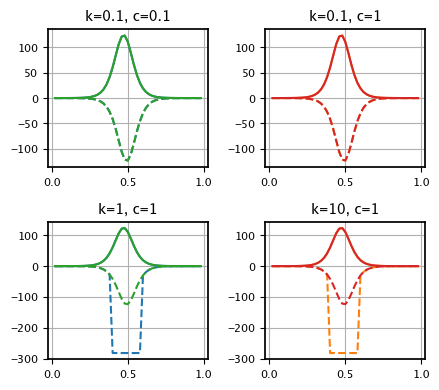

In [813]:
fig, ax_arr = plt.subplots(2, 2, figsize=(4.5, 4))
ax = np.ravel(ax_arr)

#ax[0].set_ylabel(r'$\bar{F}(l)$')
#ax[0].set_xlabel(r'$\ell$')


#ax[1].set_ylabel(r'$\Psi(l)$')
#ax[1].set_xlabel(r'$\ell$')


k = 0
l = 50
for j, (_c, color) in enumerate(zip([0.1, 1], [colors[0], colors[1]])):
    c = _c/(2*N)
    g_arr = np.arange(1, l)/l

    sp = []
    sm = []
    df_p = []
    df_m = []
    for g in g_arr:
        sp.append(2*N*seffplus_u(g, l, k, 0, gap, l0, f0, n, N))
        sm.append(2*N*seffminus_u(g, l, k, 0, gap, l0, f0, n, N))
        df_p.append(2*N*(Fitness_nb(g + 1/l, l, c, gap, l0, f0, n) - Fitness_nb(g, l, c, gap, l0, f0, n)))
        df_m.append(2*N*(Fitness_nb(g - 1/l, l, c, gap, l0, f0, n) - Fitness_nb(g, l, c, gap, l0, f0, n)))
        
        
    
    
   
    ax[j].plot(g_arr, sm, color=color, ls = '--')
    ax[j].plot(g_arr, sp, color=color,)
    ax[j].plot(g_arr, df_p, color=colors[j+2])
    ax[j].plot(g_arr, df_m, color=colors[j+2], ls = '--')


c = 1/(2*N)
for j, (k, color) in enumerate(zip([1, 10], [colors[0], colors[1]])):
    g_arr = np.arange(1, l)/l

    sp = []
    sm = []
    df_p = []
    df_m = []
    
    for g in g_arr:
        sp.append(2*N*(seffplus_u(g, l, k, 0, gap, l0, f0, n, N)))
        sm.append(2*N*(seffminus_u(g, l, k, 0, gap, l0, f0, n, N)))
        df_p.append(2*N*(Fitness_nb(g + 1/l, l, c, gap, l0, f0, n) - Fitness_nb(g, l, c, gap, l0, f0, n)))
        df_m.append(2*N*(Fitness_nb(g - 1/l, l, c, gap, l0, f0, n) - Fitness_nb(g, l, c, gap, l0, f0, n)))
        
    
    
    ax[2+j].plot(g_arr, sp, color=color,)
    ax[2+j].plot(g_arr, sm, color=color, ls = '--')
    ax[2+j].plot(g_arr, df_p, color=colors[j+2])
    ax[2+j].plot(g_arr, df_m, color=colors[j+2], ls = '--')

#ax[0].set_ylim(0.004, 0.005)
ax[0].grid(True)
ax[1].grid(True)
ax[2].grid(True)
ax[3].grid(True)


ax[0].set_title('k=0.1, c=0.1')
ax[1].set_title('k=0.1, c=1')
ax[2].set_title('k=1, c=1')
ax[3].set_title('k=10, c=1')

#ax[1].set_ylim(-100, 5)
ax[1].grid(True)

 
plt.tight_layout()
#fig.savefig('constraint_ratchet.pdf')

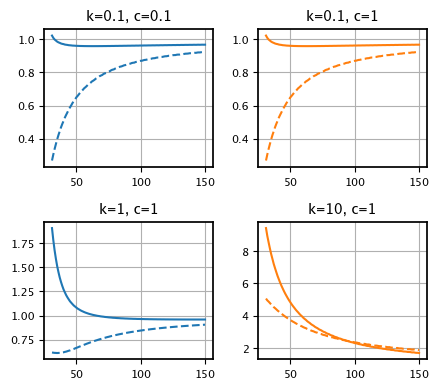

In [814]:
fig, ax_arr = plt.subplots(2, 2, figsize=(4.5, 4))
ax = np.ravel(ax_arr)

#ax[0].set_ylabel(r'$\bar{F}(l)$')
#ax[0].set_xlabel(r'$\ell$')


#ax[1].set_ylabel(r'$\Psi(l)$')
#ax[1].set_xlabel(r'$\ell$')


k = 0.1
for j, (_c, color) in enumerate(zip([0.1, 1], [colors[0], colors[1]])):
    c = _c/(2*N)
    l_arr = np.arange(lm, 151)

    sp = []
    sm = []
    for l in l_arr:
        sm.append(v_minus_star(l, k, 0, gap, l0, f0, n, N))
        sp.append(v_plus_star(l, k, 0, gap, l0, f0, n, N))
    
    
   
    ax[j].plot(l_arr, sm, color=color, ls = '--')
    ax[j].plot(l_arr, sp, color=color,)


c = 1/(2*N)
for j, (k, color) in enumerate(zip([1, 10], [colors[0], colors[1]])):
    l_arr = np.arange(lm, 151)

    sp = []
    sm = []
    for l in l_arr:
        sm.append(v_minus_star(l, k, 0, gap, l0, f0, n, N))
        sp.append(v_plus_star(l, k, 0, gap, l0, f0, n, N))
    
    
   
    ax[j+2].plot(l_arr, sm, color=color, ls = '--')
    ax[j+2].plot(l_arr, sp, color=color,)

#ax[0].set_ylim(0.004, 0.005)
ax[0].grid(True)
ax[1].grid(True)
ax[2].grid(True)
ax[3].grid(True)


ax[0].set_title('k=0.1, c=0.1')
ax[1].set_title('k=0.1, c=1')
ax[2].set_title('k=1, c=1')
ax[3].set_title('k=10, c=1')

#ax[1].set_ylim(-100, 5)
ax[1].grid(True)

 
plt.tight_layout()
#fig.savefig('constraint_ratchet.pdf')

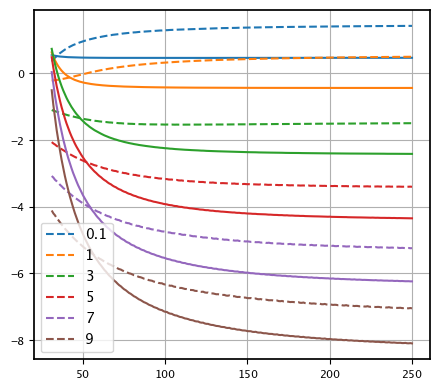

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(4.5, 4))

c = 1/(2*N)
for j, (k, color) in enumerate(zip([.1, 1, 3, 5, 7, 9], colors[:6])):
    l_arr = np.arange(lm, 251)

    sp = []
    sm = []
    for l in l_arr:
        sp.append(v_plus_star(l, k, c, gap, l0, f0, n, N))
        sm.append(v_minus_star(l, k, c, gap, l0, f0, n, N))
   
    ax.plot(l_arr, sm, color=color, ls = '--', label=k)
    ax.plot(l_arr, sp, color=color)

ax.grid(True)
ax.legend()
 
plt.tight_layout()
#fig.savefig('constraint_ratchet.pdf')

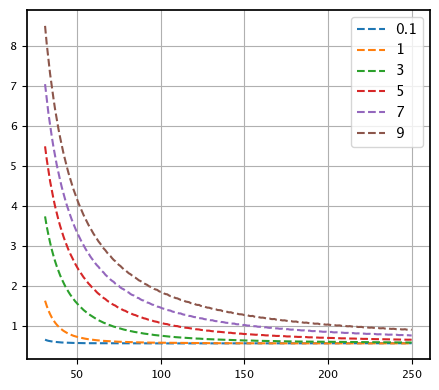

In [714]:
fig, ax = plt.subplots(1, 1, figsize=(4.5, 4))

c = 1/(2*N)
for j, (k, color) in enumerate(zip([.1, 1, 3, 5, 7, 9], colors[:6])):
    l_arr = np.arange(lm, 251)

    sp = []
    sm = []
    for l in l_arr:
        sm.append(v_plus_star(l, k, c, gap, l0, f0, n, N))
   
    ax.plot(l_arr, sm, color=color, ls = '--', label=k)

ax.grid(True)
ax.legend()
 
plt.tight_layout()
#fig.savefig('constraint_ratchet.pdf')

31
31


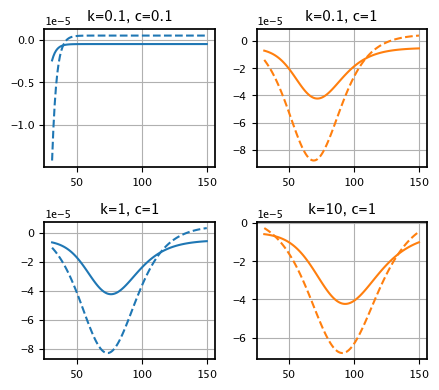

In [ ]:
fig, ax_arr = plt.subplots(2, 2, figsize=(4.5, 4))
ax = np.ravel(ax_arr)

#ax[0].set_ylabel(r'$\bar{F}(l)$')
#ax[0].set_xlabel(r'$\ell$')


#ax[1].set_ylabel(r'$\Psi(l)$')
#ax[1].set_xlabel(r'$\ell$')


k = 0.1
for j, (_c, color) in enumerate(zip([0.1, 1], [colors[0], colors[1]])):
    c = _c/(2*N)
    l_arr = np.arange(lm, 151)
    gst = gamma_star(l, k, c, gap, l0, f0, n, N)
    sp = []
    sm = []
    for l in l_arr:
        sm.append(gst * s_mm(gst, l, c, gap, l0, f0, n, N) + (1-gst) * s_mp(gst, l, c, gap, l0, f0, n, N))
        sp.append(1/4 * s_pp(gst, l, c, gap, l0, f0, n, N) + 3/4 * s_pm(gst, l, c, gap, l0, f0, n, N))
    
    
    ax[j].plot(l_arr, sm, color=color, ls = '--')
    ax[j].plot(l_arr, sp, color=color,)


c = 1/(2*N)
for j, (k, color) in enumerate(zip([1, 10], [colors[0], colors[1]])):
    l_arr = np.arange(lm, 151)
    gst = gamma_star(l, k, c, gap, l0, f0, n, N)

    sp = []
    sm = []
    print(lm)
    for l in l_arr:
        sm.append(gst * s_mm(gst, l, c, gap, l0, f0, n, N) + (1-gst) * s_mp(gst, l, c, gap, l0, f0, n, N))
        sp.append(1/4 * s_pp(gst, l, c, gap, l0, f0, n, N) + 3/4 * s_pm(gst, l, c, gap, l0, f0, n, N))
    
    
   
    ax[j+2].plot(l_arr, sm, color=color, ls = '--')
    ax[j+2].plot(l_arr, sp, color=color,)

#ax[0].set_ylim(0.004, 0.005)
ax[0].grid(True)
ax[1].grid(True)
ax[2].grid(True)
ax[3].grid(True)


ax[0].set_title('k=0.1, c=0.1')
ax[1].set_title('k=0.1, c=1')
ax[2].set_title('k=1, c=1')
ax[3].set_title('k=10, c=1')

#ax[1].set_ylim(-100, 5)
ax[1].grid(True)


plt.tight_layout()
#fig.savefig('constraint_ratchet.pdf')

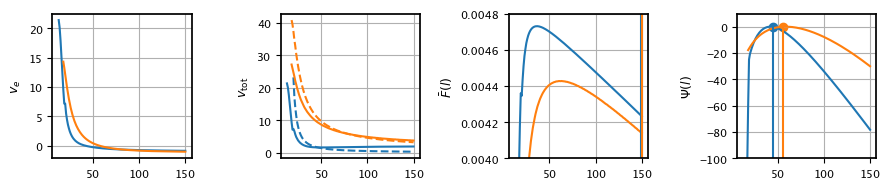

In [647]:
fig, ax = plt.subplots(1, 4, figsize=(9, 2))
ax[0].grid(True)
ax[0].set_ylabel(r'$v_e$')

ax[1].grid(True)
ax[1].set_ylabel(r'$v_\mathrm{tot}$')

ax[2].grid(True)
ax[2].set_ylabel(r'$\bar{F}(l)$')

ax[3].grid(True)
ax[3].set_ylabel(r'$\Psi(l)$')

for k, color in zip([1, 10], [colors[0], colors[1]]):
    c = 1/(2*N)

    lm, lst, flist = lstar(k, c, N=N, lmax=150)
    flist = flist[0:]
    lm = lm+0
    flist = flist - np.max(flist)
    F_arr = []
    l_arr = np.arange(lm, 151)
    v_e_arr = []
    v_theo = []
    v_theo_l = []
    v_tot_arr = []
    for l in l_arr:
        gst = gamma_star(l, k, c)
        F = Fitness_nb(gst, l, 0, gap, l0, f0, n)
        F_arr.append(F)
        v_e = v_plus_star(l, k, c, gap, l0, f0, n, N) - v_minus_star(l, k, c, gap, l0, f0, n, N)
        v_e_arr.append(v_e)
        v_tot = v_plus_star(l, k, c, gap, l0, f0, n, N) + v_minus_star(l, k, c, gap, l0, f0, n, N)
        v_tot_arr.append(v_tot)
        if gst < 1:
            v_theo.append(.3 * k * (gst - 1/4)/(1/4 * (1-gst)))
            v_theo_l.append(l)
    

    ax[0].plot(l_arr, v_e_arr, color=color)
    
    ax[1].plot(l_arr, v_tot_arr, color=color)
    ax[1].plot(v_theo_l, v_theo, color=color, ls='--')

    ax[2].plot(l_arr, F_arr - l_arr * c, color=color)
    ax[3].plot(l_arr, flist, color=color)


for k, color in zip([1, 10], [colors[0], colors[1]]):
    c = 1/(2*N)

    lm, lst, flist = lstar(k, c, N=N, lmax=150)
    flist = flist[2:]
    lm = lm+2
    flist = flist - np.max(flist)
    F_arr = []
    for l in l_arr:
        gst = gamma_star(l, k, c)
        F = 2*N* Fitness_nb(gst, l, 0, gap, l0, f0, n)
        F_arr.append(F)
    
    ymin, ymax_plot = ax[2].get_ylim()
    ind = np.argmax(F_arr- l_arr * c)
    ax[2].scatter(l_arr[ind], (F_arr - l_arr * c)[ind], color=color)
    ax[2].vlines(l_arr[ind], ymin, (F_arr- l_arr * c)[ind], color=color)
    

    ind = np.argmax(flist)
    ymin, ymax_plot = ax[3].get_ylim()
    ax[3].scatter(l_arr[ind], flist[ind], color=color)
    ax[3].vlines(l_arr[ind], ymin, flist[ind], color=color)


ax[2].set_ylim(0.004, 0.0048)
ax[3].set_ylim(-100, 10)


fig.tight_layout()

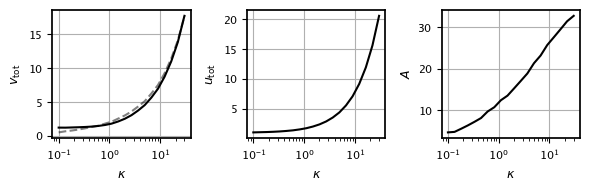

In [655]:
fig, ax_arr = plt.subplots(1, 3, figsize=(6, 2))
ax = np.ravel(ax_arr)

ax[0].set_xscale('log')
ax[0].set_xlabel(r'$\kappa$')
ax[1].set_xscale('log')
ax[1].set_xlabel(r'$\kappa$')
ax[2].set_xscale('log')
ax[2].set_xlabel(r'$\kappa$')
#ax[3].set_xscale('log')
#ax[3].set_xlabel(r'$\kappa$')

ax[0].set_ylabel(r'$v_\mathrm{tot}$')
ax[2].set_ylabel(r'$A$')
ax[1].set_ylabel(r'$u_\mathrm{tot}$')


k_arr = np.logspace(-1, np.log10(30), num=20)

_c = 1
v_e = []
v_tot = []
v_theo = []
A_arr = []
u_arr = []

for k in k_arr:
    c = _c / (2*N)
    lm, lst, _ = lstar(k, c, N=N, lmax=300)
    
    gst = gamma_star(lst, k, c)
   
    v_e.append(v_plus_star(lst, k, c, gap, l0, f0, n, N) - v_minus_star(lst, k, c, gap, l0, f0, n, N))
    v_tot.append(v_plus_star(lst, k, c, gap, l0, f0, n, N) + v_minus_star(lst, k, c, gap, l0, f0, n, N))
    A_arr.append(lst * (1-gst))
    v_theo.append(.3*k*(gst - 1/4)/(1/4 * (1-gst)))
    u_arr.append(up_nb(gst, l, k, c, gap, l0, f0, n, N) + um_nb(gst, l, k, c, gap, l0, f0, n, N))

ax[0].plot(k_arr, v_tot, color="black")
ax[0].plot(k_arr, v_theo, color="black", ls='--', alpha=0.5)  
ax[1].plot(k_arr, u_arr, color="black")
ax[2].plot(k_arr, A_arr, 'black') 


for _ax in ax:
    #_ax.label_outer() # Apply label_outer() to each subplot
    _ax.grid(True)

fig.tight_layout(h_pad=0, w_pad=1)
#fig.subplots_adjust(right=0.8)  

fig.savefig('adaptive_ratchet.pdf')

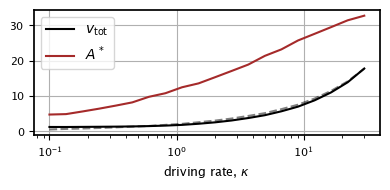

In [140]:
fig, ax = plt.subplots(1, 1, figsize=(4, 2))


ax.set_xscale('log')
ax.set_xlabel('driving rate, ' + r'$\kappa$')
#ax[3].set_xlabel(r'$\kappa$')


k_arr = np.logspace(-1, np.log10(30), num=20)

_c = 1
v_e = []
v_tot = []
v_theo = []
A_arr = []
u_arr = []

for k in k_arr:
    c = _c / (2*N)
    lm, lst, _ = lstar(k, c, N=N, lmax=300)
    
    gst = gamma_star(lst, k, c)
   
    v_e.append(v_plus_star(lst, k, c, gap, l0, f0, n, N) - v_minus_star(lst, k, c, gap, l0, f0, n, N))
    v_tot.append(v_plus_star(lst, k, c, gap, l0, f0, n, N) + v_minus_star(lst, k, c, gap, l0, f0, n, N))
    A_arr.append(lst * (1-gst))
    v_theo.append(.3*k*(gst - 1/4)/(1/4 * (1-gst)))
    u_arr.append(up_nb(gst, lst, k, c, gap, l0, f0, n, N) + um_nb(gst, lst, k, c, gap, l0, f0, n, N))

ax.plot(k_arr, v_tot, color="black", label=r'$v_\mathrm{tot}$')
ax.plot(k_arr, v_theo, color="black", ls='--', alpha=0.5)  
#ax.plot(k_arr, u_arr, color="black")
ax.plot(k_arr, A_arr, 'brown', label=r'$A^*$') 

# Apply label_outer() to each subplot
ax.grid(True)
ax.legend(loc='best')
fig.tight_layout(h_pad=0, w_pad=1)
#fig.subplots_adjust(right=0.8)  

fig.savefig('adaptive_tinkering_flat.pdf')

## Numerics

In [515]:


# ---- Numba helpers for transitions / selection (NB versions) ----
@njit
def gamma_pp_nb(g, l):
    # transition uses previous l
    v = (g + 1.0/l) / (1.0 + 1.0/l)
    return min(v, 1.0)

@njit
def gamma_pm_nb(g, l):
    v = g / (1.0 + 1.0/l)
    return max(v, 0.0)

@njit
def gamma_mp_nb(g, l):
    v = g / (1.0 - 1.0/l)
    return min(v, 1.0)

@njit
def gamma_mm_nb(g, l):
    v = (g - 1.0/l) / (1.0 - 1.0/l)
    return max(v, 0.0)

@njit
def s_pp_nb(g, l, c, gap, l0, f0, n):
    return Fitness_nb(gamma_pp_nb(g, l), l+1, c, gap, l0, f0, n) - Fitness_nb(g, l, c, gap, l0, f0, n)

@njit
def s_pm_nb(g, l, c, gap, l0, f0, n):
    return Fitness_nb(gamma_pm_nb(g, l), l+1, c, gap, l0, f0, n) - Fitness_nb(g, l, c, gap, l0, f0, n)

@njit
def s_mm_nb(g, l, c, gap, l0, f0, n):
    return Fitness_nb(gamma_mm_nb(g, l), l-1, c, gap, l0, f0, n) - Fitness_nb(g, l, c, gap, l0, f0, n)

@njit
def s_mp_nb(g, l, c, gap, l0, f0, n):
    return Fitness_nb(gamma_mp_nb(g, l), l-1, c, gap, l0, f0, n) - Fitness_nb(g, l, c, gap, l0, f0, n)

@njit
def v_pp_nb(g, l, c, gap, l0, f0, n, N):
    return gamma0_nb(n) * g_rate_nb(s_pp_nb(g, l, c, gap, l0, f0, n), N)

@njit
def v_pm_nb(g, l, c, gap, l0, f0, n, N):
    return (1.0 - gamma0_nb(n)) * g_rate_nb(s_pm_nb(g, l, c, gap, l0, f0, n), N)

@njit
def v_mm_nb(g, l, c, gap, l0, f0, n, N):
    return g * g_rate_nb(s_mm_nb(g, l, c, gap, l0, f0, n), N)

@njit
def v_mp_nb(g, l, c, gap, l0, f0, n, N):
    return (1.0 - g) * g_rate_nb(s_mp_nb(g, l, c, gap, l0, f0, n), N)

@njit
def v_plus_nb2(g, l, c, gap, l0, f0, n, N):
    return v_pp_nb(g, l, c, gap, l0, f0, n, N) + v_pm_nb(g, l, c, gap, l0, f0, n, N)

@njit
def v_minus_nb2(g, l, c, gap, l0, f0, n, N):
    return v_mm_nb(g, l, c, gap, l0, f0, n, N) + v_mp_nb(g, l, c, gap, l0, f0, n, N)

# ---- stable softmax for log-weights, all Numba ----
@njit
def _softmax_from_logw_nb(logw):
    m = np.max(logw)
    e = np.exp(logw - m)
    return e / np.sum(e)

@njit
def init_nb(l, kappa, c, gap, l0, f0, n, N):
    """
    Sample initial gamma from Ψ_k using stable softmax + inverse CDF.
    Strictly uses the parameters passed in (no globals).
    """
    plist = Psi_k_nb(l, kappa, c, gap, l0, f0, n, N)  # length l+1 (unnormalized log-weights)
    probs = _softmax_from_logw_nb(plist)
    # cumulative
    cdf = np.empty_like(probs)
    s = 0.0
    for i in range(probs.size):
        s += probs[i]
        cdf[i] = s
    # draw
    r = np.random.random()
    # first index where cdf > r
    idx = 0
    while idx < cdf.size and not (cdf[idx] > r):
        idx += 1
    if idx == cdf.size:
        idx = cdf.size - 1
    return idx / float(l)  # (k-1)/l with 0-based idx

@njit
def get_rates(gamma, l, kappa, nu, c, gap, l0, f0, n, N):
    # choose steps
    # trait beneficial
    r1 = up_nb(gamma, l, 0, c, gap, l0, f0, n, N)
    # target beneficial
    r2 =  up_nb(gamma, l, kappa, c, gap, l0, f0, n, N) - up_nb(gamma, l, 0, c, gap, l0, f0, n, N)
    # trait deleterious
    r3 = um_nb(gamma, l, 0, c, gap, l0, f0, n, N)
    # target deleterious
    r4 = um_nb(gamma, l, kappa, c, gap, l0, f0, n, N) - um_nb(gamma, l, 0, c, gap, l0, f0, n, N) 
    # length increase beneficial
    r5 = nu * v_pp_nb(gamma, l, c, gap, l0, f0, n, N)
    # length increase del
    r6 = nu * v_pm_nb(gamma, l, c, gap, l0, f0, n, N)
    # length decrease beneficial
    r7 = nu * v_mp_nb(gamma, l, c, gap, l0, f0, n, N)
    # length decrease del
    r8 = nu * v_mm_nb(gamma, l, c, gap, l0, f0, n, N)
    return np.array([r1, r2, r3, r4, r5, r6, r7, r8])

@njit
def gillespie_step(rates, gamma, l):
    r_sum = np.sum(rates)

    r = np.random.rand() * r_sum
    if r < rates[0]:
        gamma = gamma + 1.0 / l
        mutation_type = 1
    elif r < rates[0] + rates[1]:
        gamma = gamma + 1 / l
        mutation_type = 2
    elif r < rates[0] + rates[1] + rates[2]:
        gamma = gamma - 1/l
        mutation_type = 3
    elif r < rates[0] + rates[1] + rates[2] + rates[3]:
        gamma = gamma - 1/l
        mutation_type = 4
    elif r < rates[0] + rates[1] + rates[2] + rates[3] + rates[4]:
        gamma = (gamma * l + 1.0) / (l+1)
        l = l + 1
        mutation_type = 5
    elif r < rates[0] + rates[1] + rates[2] + rates[3] + rates[4] + rates[5]:
        gamma = (gamma * l) / (l+1)
        l = l + 1
        mutation_type = 6
    elif r < rates[0] + rates[1] + rates[2] + rates[3] + rates[4] + rates[5] + rates[6]:
        gamma = (gamma * l) / (l-1)
        l = l - 1
        mutation_type = 7
    else:
        gamma = (gamma * l - 1) / (l-1)
        l = l - 1
        mutation_type = 8
    if r_sum == 0:
        raise Exception("All rates are zero.") 
        
    return gamma, l, mutation_type, np.random.exponential(1.0 / r_sum)





@njit
def evol_nb(l_init, kappa, t, nu,
                            c, gap, l0, f0, n, N,
                            t0=1, seed=0, l_min=2):
    #np.random.seed(seed)
    # init
    l = int(l_init)
    if l < l_min:
        l = l_min
    gamma = init_nb(l, kappa, c, gap, l0, f0, n, N)

    # warmup (no logging)
    for _ in range(max(0, t0 - 1)):
        rates = get_rates(gamma, l, kappa, nu, c, gap, l0, f0, n, N)
        gamma, l, mutation_type, _t = gillespie_step(rates, gamma, l)

    ev_kind_step = np.empty(t, dtype=np.int8)
    ev_l_step    = np.empty(t+1, dtype=np.int64)
    ev_g_step    = np.empty(t+1, dtype=np.float64)
    ev_t_step    = np.empty(t, dtype=np.float64)
    ev_l_step[0] = l
    ev_g_step[0] = gamma

    for step in range(1, t + 1):
        rates = get_rates(gamma, l, kappa, nu, c, gap, l0, f0, n, N)
        gamma, l, mutation_type, _t = gillespie_step(rates, gamma, l)
        ev_l_step[step] = l
        ev_g_step[step] = gamma
        ev_kind_step[step-1] = mutation_type
        ev_t_step[step-1] = _t

            
    return ev_g_step, ev_l_step, ev_kind_step, ev_t_step
    

In [ ]:
colors = {
    1:  "#2ca02c",  # trait: adaptive
    3:  "#d62728",  # trait: deleterious
    2:  "gray",  # trait: external improvement
    4:  "gray",  # trait: external degradation
    5: "gray",  # length: extension (γ_pp)
    6: "gray",  # length: extension (γ_pm)
    7: "gray",  # length: compression (γ_mp)
    8: "gray",  # length: compression (γ_mm)
}


In [577]:
def get_colors_trait(steps):
    colors = {
        1:  "#2ca02c",  # trait: adaptive
        3:  "#d62728",  # trait: deleterious
        2: (0, 0, 0, 0),  # trait: external improvement
        4: (0, 0, 0, 0),  # trait: external degradation
        5: (0, 0, 0, 0),  # length: extension (γ_pp)
        6: (0, 0, 0, 0),  # length: extension (γ_pm)
        7: (0, 0, 0, 0),  # length: compression (γ_mp)
        8: (0, 0, 0, 0),  # length: compression (γ_mm)
    }
    colors_list = []
    for step in steps:
        colors_list.append(colors[step])

    return colors_list


def get_colors_length(steps):
    colors = {
        1:  (0, 0, 0, 0),  # trait: adaptive
        3:  (0, 0, 0, 0),  # trait: deleterious
        2:  (0, 0, 0, 0),  # trait: external improvement
        4:  (0, 0, 0, 0),  # trait: external degradation
        5: "orange",  # length: extension (γ_pp)
        6: "orange",  # length: extension (γ_pm)
        7: "purple",  # length: compression (γ_mp)
        8: "purple",  # length: compression (γ_mm)
    }
    colors_list = []
    for step in steps:
        colors_list.append(colors[step])

    return colors_list




def get_colors_type(steps):
    colors = {
        1:  "brown",      # trait: adaptive
        3:  "brown",      # trait: deleterious
        2:  "#738fc1",       # trait: external improvement
        4:  "#738fc1",       # trait: external degradation
        5: (0, 0, 0, 0),  # length: extension (γ_pp)
        6: (0, 0, 0, 0),  # length: extension (γ_pm)
        7: (0, 0, 0, 0),  # length: compression (γ_mp)
        8: (0, 0, 0, 0),  # length: compression (γ_mm)
    }
    colors_list = []
    for step in steps:
        colors_list.append(colors[step])

    return colors_list
        

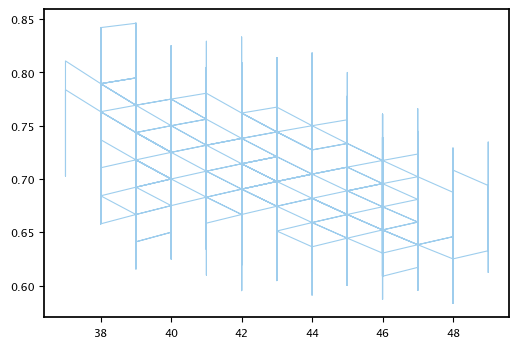

In [474]:
l_init = 100
t = 10000
nu = 0.01
kappa = 1
c = 1/(2*N)
t0 = 1000000
seed = 42

g_track, l_track,_, _ = evol_nb(l_init, kappa, t, nu,
                            c, gap, l0, f0, n, N,
                            t0=t0, seed=seed, l_min=2
)

#color_steps1 = [colors[x] for x in set1['ev_kind_step']]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(l_track, g_track, color="#5dade2", lw=0.8, alpha=0.6)

#ax.scatter(set1['ev_l_step'], set1['ev_g_step'], s=20, c=color_steps1, edgecolors="none", alpha=1)

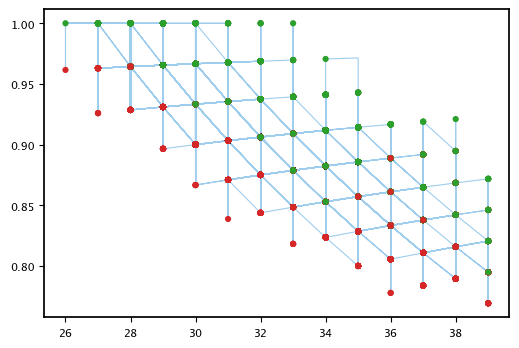

In [475]:
l_init = 100
t = 10000
nu = 0.01
kappa = 0
c = 1/(2*N)
t0 = 1000000
seed = 42

g_track, l_track, mut_list, t_list= evol_nb(l_init, kappa, t, nu,
                            c, gap, l0, f0, n, N,
                            t0=t0, seed=seed, l_min=2
)


color_steps1 = get_colors(mut_list)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(l_track, g_track, color="#5dade2", lw=0.8, alpha=0.6)

ax.scatter(l_track[1:], g_track[1:], s=20, c=color_steps1, edgecolors="none", zorder=3)

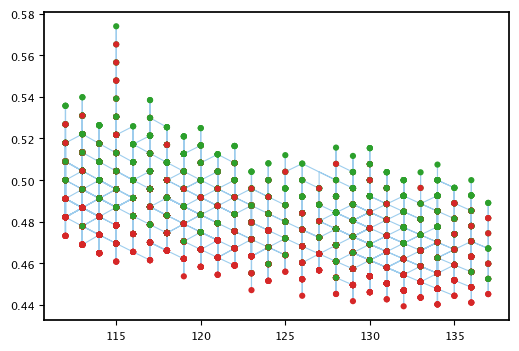

In [476]:
l_init = 100
t = 10000
nu = 0.01
kappa = 0
c = .1/(2*N)
t0 = 1000000
seed = 42

g_track, l_track, mut_list, t_list = evol_nb(l_init, kappa, t, nu,
                            c, gap, l0, f0, n, N,
                            t0=t0, seed=seed, l_min=2
)

#color_steps1 = [colors[x] for x in set1['ev_kind_step']]
color_steps1 = get_colors(mut_list)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(l_track, g_track, color="#5dade2", lw=0.8, alpha=0.6)

ax.scatter(l_track[1:], g_track[1:], s=20, c=color_steps1, edgecolors="none", zorder=3)

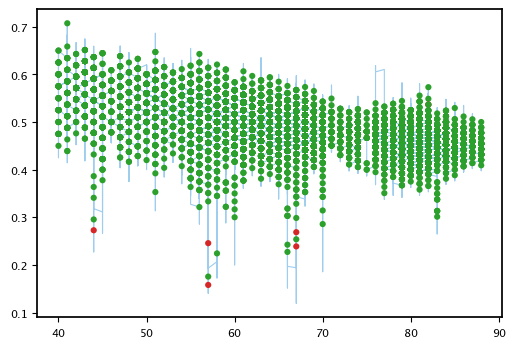

In [477]:
l_init = 100
t = 100000
nu = 0.01
kappa = 30
c = 1/(2*N)
t0 = 1000000
seed = 42

g_track, l_track, mut_list, t_list = evol_nb(l_init, kappa, t, nu,
                            c, gap, l0, f0, n, N,
                            t0=t0, seed=seed, l_min=2
)

#color_steps1 = [colors[x] for x in set1['ev_kind_step']]
color_steps1 = get_colors(mut_list)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(l_track, g_track, color="#5dade2", lw=0.8, alpha=0.6)

ax.scatter(l_track[1:], g_track[1:], s=20, c=color_steps1, edgecolors="none", zorder=3)

In [478]:
def gray_ramp(dark='#222222', light='#ffffff', name='gray_ramp'):
    """Continuous colormap from `light` to `dark`."""
    return LinearSegmentedColormap.from_list(name, [light, dark], N=256)

cmap = gray_ramp(dark='#80808080')
cmap_orange = LinearSegmentedColormap.from_list(
    "cmap_orange",
    [(1.0, 1.0, 1.0, 0.0),  # start: white, fully transparent
     (1.0, 0.65, 0.0, 1.0)],# end: orange, fully opaque
    N=100
)

In [ ]:
# g_track_adapt, l_track_adapt, mut_list_adapt, t_list_adapt = evol_nb(l_init, kappa, 10**4, nu,
#                             c, gap, l0, f0, n, N,
#                             t0=10**5, seed=seed, l_min=2
# )

In [532]:
# g_track_base, l_track_base, mut_list_base, t_list_base = evol_nb(l_init, 0, 10**3, nu,
#                             1/(2*N), gap, l0, f0, n, N,
#                             t0=10**5, seed=seed, l_min=2
# )

In [ ]:

# g_track_constraint, l_track_constraint, mut_list_constraint, t_list_constraint = evol_nb(l_init, 0, 10**3, nu,
#                             0.1/(2*N), gap, l0, f0, n, N,
#                             t0=10**5, seed=seed, l_min=2)

/var/folders/67/2rd1gct91876bvjs_7ny9rcw0000gn/T/ipykernel_2264/2607875186.py:150: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


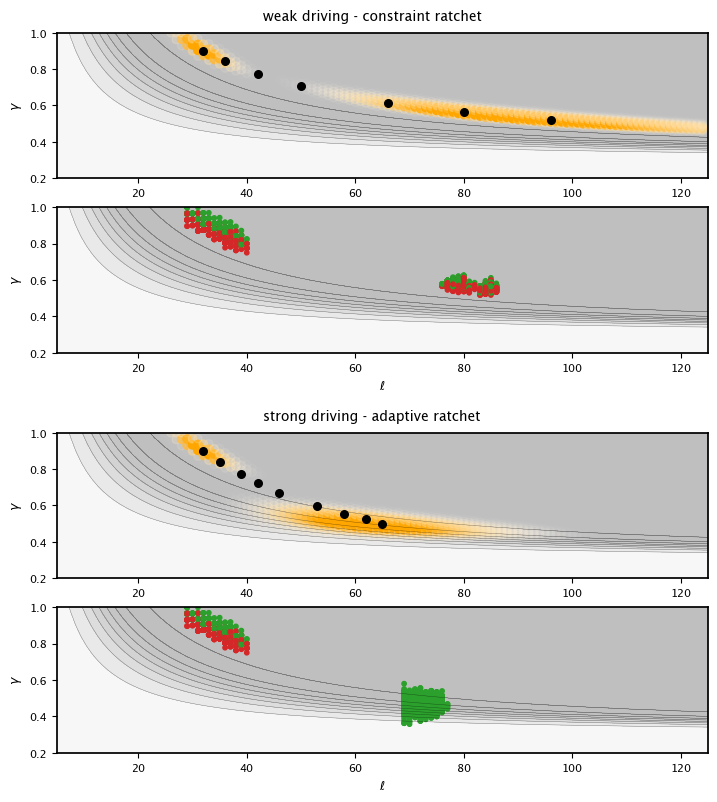

In [536]:
fig = plt.figure(figsize=(7, 8))

gs1 = GridSpec(2, 1, left=0.05, right=0.98, top=0.95, bottom=0.55)
ax1 = fig.add_subplot(gs1[0, 0])
ax2 = fig.add_subplot(gs1[1, 0])

gs2 = GridSpec(2, 1, left=0.05, right=0.98, top=0.45, bottom=0.05)
ax3 = fig.add_subplot(gs2[0, 0])
ax4 = fig.add_subplot(gs2[1, 0])

ax = [ax1, ax2, ax3, ax4]

# Helper to draw the shared contour background
def draw_background(ax, L_grid, G_grid, F, Levels=8):
    cf = ax.contourf(L_grid, G_grid, F, levels=Levels, cmap=cmap, extend='max')
    ax.contour(L_grid, G_grid, F, levels=Levels, linewidths=0.3, colors='black', alpha=0.5)
    ax.set_ylim(0.2, 1.0)
    return cf


def fitness_field(lmin, lmax, dgamma, c, gap, l0, f0, n):
    """
    Build F(gamma, l) on a regular grid for contouring.
    Returns L_grid (1D), G_grid (1D), F (2D with shape (len(G), len(L))).
    """
    L = np.arange(lmin, lmax+1, dtype=int)
    G = np.arange(0.0, 1.0 + 1e-12, dgamma)
    F = np.empty((G.size, L.size), dtype=float)
    for j, l in enumerate(L):
        for i, g in enumerate(G):
            F[i, j] = Fitness_nb(g, l, c, gap, l0, f0, n)
    return L, G, F


L, G, F = fitness_field(5, 125, 0.01, 0, gap, l0, f0, n)

draw_background(ax[0], L, G, F, Levels=8)
draw_background(ax[1], L, G, F, Levels=8)
draw_background(ax[2], L, G, F, Levels=8)
draw_background(ax[3], L, G, F, Levels=8)


# constrain ratchet
c = 1/(2*N)
lm, lst, flist = lstar(0, c, lmax=200)
f_norm = np.log(np.sum(np.exp(flist)))
gst = gamma_star(lst, 0, c)
Q_List = []
g_list = []
l_list = []
for i, l in enumerate(np.arange(lm, 125)):
    psi = Psi_k_nb(l, 0, c, gap, l0, f0, n, N)
    psi = psi - np.max(psi)
    psi_norm = np.log(np.sum(np.exp(psi))* l)
    gamma_list = np.arange(0, l+1)/l
    g_list.extend(gamma_list)
    l_list.extend(np.ones(l+1)*l)
    Q = np.exp(psi + flist[i] - f_norm - psi_norm)
    Q_List.extend(Q)
    
ax[0].scatter(l_list, g_list, c=np.ravel(Q_List), cmap=cmap_orange, vmax=np.max(np.ravel(Q_List)) * 0.7, vmin=0)
ax[2].scatter(l_list, g_list, c=np.ravel(Q_List), cmap=cmap_orange, vmax=np.max(np.ravel(Q_List)) * 0.7, vmin=0)


color_steps1 = get_colors_trait(mut_list_base)
ax[1].scatter(l_track_base[1:], g_track_base[1:], s=10, color=color_steps1)
ax[3].scatter(l_track_base[1:], g_track_base[1:], s=10, color=color_steps1)

# constrain ratchet
c = .1/(2*N)
lm, lst, flist = lstar(0, c, lmax=200)
f_norm = np.log(np.sum(np.exp(flist)))
gst = gamma_star(lst, 0, c)
Q_List = []
g_list = []
l_list = []
for i, l in enumerate(np.arange(lm, 125)):
    psi = Psi_k_nb(l, 0, c, gap, l0, f0, n, N)
    psi = psi - np.max(psi)
    psi_norm = np.log(np.sum(np.exp(psi))* l)
    gamma_list = np.arange(0, l+1)/l
    g_list.extend(gamma_list)
    l_list.extend(np.ones(l+1)*l)
    Q = np.exp(psi + flist[i] - f_norm - psi_norm)
    Q_List.extend(Q)
    


ax[0].scatter(l_list, g_list, c=np.ravel(Q_List), cmap=cmap_orange, vmax=np.max(np.ravel(Q_List)) * 0.7, vmin=0)
color_steps1 = get_colors_trait(mut_list_constraint)
ax[1].scatter(l_track_constraint[1:], g_track_constraint[1:], s=10, color=color_steps1)


# adaptive ratchet
c = 1/(2*N)
kappa = 30
lm, lst, flist = lstar(kappa, c, lmax=200)
f_norm = np.log(np.sum(np.exp(flist)))
gst = gamma_star(lst, kappa, c)
Q_List = []
g_list = []
l_list = []
for i, l in enumerate(np.arange(lm, 125)):
    psi = Psi_k_nb(l, kappa, c, gap, l0, f0, n, N)
    psi = psi - np.max(psi)
    psi_norm = np.log(np.sum(np.exp(psi))* l)
    gamma_list = np.arange(0, l+1)/l
    g_list.extend(gamma_list)
    l_list.extend(np.ones(l+1)*l)
    Q = np.exp(psi + flist[i] - f_norm - psi_norm)
    Q_List.extend(Q)
    
ax[2].scatter(l_list, g_list, c=np.ravel(Q_List), cmap=cmap_orange, vmax=np.max(np.ravel(Q_List)) * 0.7, vmin=0)
color_steps1 = get_colors(mut_list_adapt)
ax[3].scatter(l_track_adapt[1:], g_track_adapt[1:], s=10, color=color_steps1)

# plot trajectories
#ax[1].scatter(set1['ev_l_step'][::10], set1['ev_g_step'][::10], s=10, c=color_steps1[::10], edgecolors="none", alpha=1)
#ax[1].scatter(set2['ev_l_step'][::10], set2['ev_g_step'][::10], s=10, c=color_steps2[::10], edgecolors="none", alpha=1)
#ax[3].scatter(set3['ev_l_step'][::10], set3['ev_g_step'][::10], s=10, c=color_steps3[::10], edgecolors="none", alpha=1)
#ax[3].scatter(set4['ev_l_step'][::10], set4['ev_g_step'][::10], s=10, c=color_steps4[::10], edgecolors="none", alpha=1)

for _c in [1, 0.7, 0.5, 0.35, 0.2, 0.14, 0.1]:
    c = _c/(2*N)
    lm, lst, flist = lstar(0, c, lmax=200)
    f_norm = np.log(np.sum(np.exp(flist)))
    gst = gamma_star(lst, 0, c)
    ax[0].scatter([lst] ,[gst], s=30, color="black")

for k in [0, 0.2, 0.5, 1, 2, 5, 10, 15, 30]:
    c = 1/(2*N)
    lm, lst, flist = lstar(k, c, lmax=200)
    f_norm = np.log(np.sum(np.exp(flist)))
    gst = gamma_star(lst, k, c)
    ax[2].scatter([lst] ,[gst], s=30, color="black")




ax[1].set_xlabel(r'$\ell$')
ax[3].set_xlabel(r'$\ell$')

ax[0].set_ylabel(r'$\gamma$')
ax[1].set_ylabel(r'$\gamma$')
ax[2].set_ylabel(r'$\gamma$')
ax[3].set_ylabel(r'$\gamma$')

fig.text(0.5, 0.47, "strong driving - adaptive ratchet", horizontalalignment='center', verticalalignment='center')
fig.text(0.5, 0.97, "weak driving - constraint ratchet", horizontalalignment='center', verticalalignment='center')
fig.tight_layout()
#fig.savefig("numerics_main.pdf")

In [573]:
g_track_loss, l_track_loss, mut_list_loss, t_list_loss = evol_nb(30, 100, 10**5, nu,
                            c, gap, l0, f0, n, N,
                            t0=0, seed=seed, l_min=2)

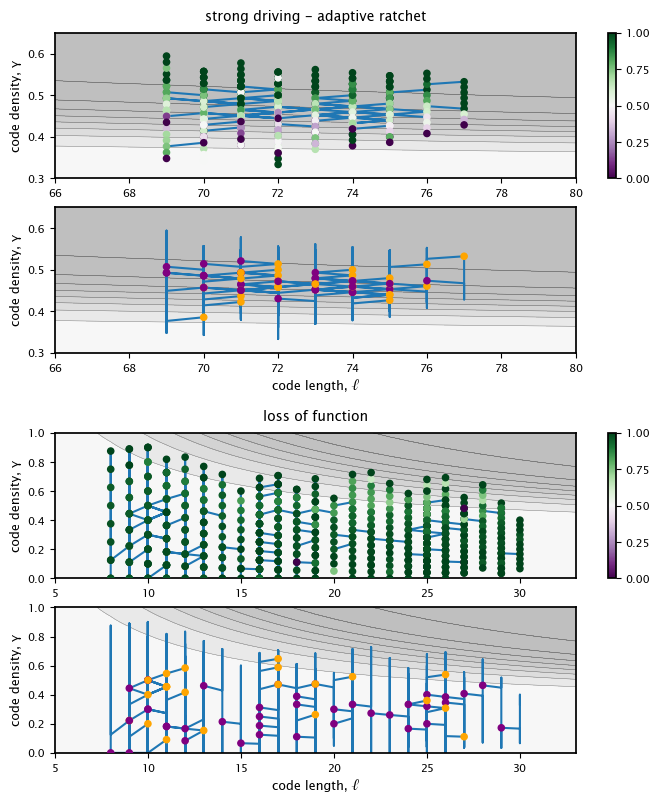

In [624]:
fig = plt.figure(figsize=(7, 8))

gs1 = GridSpec(2, 1, left=0.05, right=0.98, top=0.95, bottom=0.55)
ax1 = fig.add_subplot(gs1[0, 0])
ax11 = fig.add_subplot(gs1[1, 0])

gs2 = GridSpec(2, 1, left=0.05, right=0.98, top=0.45, bottom=0.05)
ax2 = fig.add_subplot(gs2[0, 0])
ax22 = fig.add_subplot(gs2[1, 0])

ax = [ax1, ax11, ax2, ax22]

# Helper to draw the shared contour background
def draw_background(ax, L_grid, G_grid, F, Levels=8):
    cf = ax.contourf(L_grid, G_grid, F, levels=Levels, cmap=cmap, extend='max')
    ax.contour(L_grid, G_grid, F, levels=Levels, linewidths=0.3, colors='black', alpha=0.5)
    #ax.set_ylim(0.2, 1.0)
    return cf


def fitness_field(lmin, lmax, dgamma, c, gap, l0, f0, n):
    """
    Build F(gamma, l) on a regular grid for contouring.
    Returns L_grid (1D), G_grid (1D), F (2D with shape (len(G), len(L))).
    """
    L = np.arange(lmin, lmax+1, dtype=int)
    G = np.arange(0.0, 1.0 + 1e-12, dgamma)
    F = np.empty((G.size, L.size), dtype=float)
    for j, l in enumerate(L):
        for i, g in enumerate(G):
            F[i, j] = Fitness_nb(g, l, c, gap, l0, f0, n)
    return L, G, F


# Draw fitness landscape
L, G, F = fitness_field(1, 125, 0.01, 0, gap, l0, f0, n)
draw_background(ax[0], L, G, F, Levels=8)
draw_background(ax[1], L, G, F, Levels=8)
draw_background(ax[2], L, G, F, Levels=8)
draw_background(ax[3], L, G, F, Levels=8)


# Plot paths
steps=5000
ax[0].plot(l_track_adapt[1:], g_track_adapt[1:])
ax[1].plot(l_track_adapt[1:], g_track_adapt[1:])

ax[2].plot(l_track_loss[1:], g_track_loss[1:])
ax[3].plot(l_track_loss[1:], g_track_loss[1:])     


# Get type of mutations for plots for adaptive path
point_data = defaultdict(lambda: [0, 0])

for l, g, action in zip(l_track_adapt, g_track_adapt, mut_list_adapt):
    if (action == 1) or (action == 3): 
        point_data[(l, g)][1] += 1
    elif (action == 2) or (action == 4): 
        point_data[(l, g)][0] += 1


unique_x = []
unique_y = []
color_values = []

for point, (count_A, count_B) in point_data.items():
    total = count_A + count_B
    if total > 0:
        frequency_A = count_A / total
        
        unique_x.append(point[0])
        unique_y.append(point[1])
        color_values.append(frequency_A)

custom_colors = [
    (0.0, "#738fc1"),   # 0.0 = All Action B
    #(0.5, "white"),  # 0.5 = Equal A and B
    (1.0, "brown")     # 1.0 = All Action A
]
my_cmap = LinearSegmentedColormap.from_list("my_custom_cmap", custom_colors)
my_cmap = "PRGn"
sc = ax[0].scatter(unique_x, unique_y, c=color_values, cmap=my_cmap, zorder=3, s=20)


# get mutation types for loss path
point_data = defaultdict(lambda: [0, 0])

for l, g, action in zip(l_track_loss, g_track_loss, mut_list_loss):
    if (action == 1) or (action == 3): 
        point_data[(l, g)][1] += 1
    elif (action == 2) or (action == 4): 
        point_data[(l, g)][0] += 1


unique_x = []
unique_y = []
color_values = []

for point, (count_A, count_B) in point_data.items():
    total = count_A + count_B
    if total > 0:
        frequency_A = count_A / total
        
        unique_x.append(point[0])
        unique_y.append(point[1])
        color_values.append(frequency_A)

custom_colors = [
    (0.0, "#738fc1"),   # 0.0 = All Action B
    #(0.5, "white"),  # 0.5 = Equal A and B
    (1.0, "brown")     # 1.0 = All Action A
]


sc2 = ax[2].scatter(unique_x, unique_y, c=color_values, cmap=my_cmap, zorder=3, s=20)


# Plot length changes

color_steps1 = get_colors_length(mut_list_adapt)
ax[1].scatter(l_track_adapt[1:], g_track_adapt[1:], c=color_steps1, zorder=3, s=20)

color_steps1 = get_colors_length(mut_list_loss)
ax[3].scatter(l_track_loss[1:], g_track_loss[1:], c=color_steps1, zorder=3, s=20)

ax[2].set_xlabel(r'$\ell$')
ax[3].set_xlabel(r'$\ell$')

ax[0].set_ylabel(r'$\gamma$')
ax[2].set_ylabel(r'$\gamma$')


ax[0].set_xlim(np.min(l_track_adapt)-3, np.max(l_track_adapt)+3)
ax[1].set_xlim(np.min(l_track_adapt)-3, np.max(l_track_adapt)+3)
ax[2].set_xlim(np.min(l_track_loss)-3, np.max(l_track_loss)+3)
ax[3].set_xlim(np.min(l_track_loss)-3, np.max(l_track_loss)+3)

ax[0].set_ylim(0.3, 0.65)
ax[1].set_ylim(0.3, 0.65)

cbar1 = plt.colorbar(sc, ax=ax[0], ticks=[0, 0.25, 0.5, 0.75, 1])
cbar2 = plt.colorbar(sc2, ax=ax[2], ticks=[0, 0.25, 0.5, 0.75, 1])


pos0 = ax[0].get_position()
pos2 = ax[2].get_position()

pos1 = ax[1].get_position()
pos3 = ax[3].get_position()

ax[1].set_position([pos0.x0, pos1.y0, pos0.width, pos1.height])
ax[3].set_position([pos2.x0, pos3.y0, pos2.width, pos3.height])

plot_center_x = pos0.x0 + pos0.width / 2
fig.text(plot_center_x, 0.97, "strong driving - adaptive ratchet", horizontalalignment='center', verticalalignment='center')
fig.text(plot_center_x, 0.47, "loss of function", horizontalalignment='center', verticalalignment='center')

ax[0].set_ylabel('code density, \u03B3')
ax[1].set_ylabel('code density, \u03B3')
ax[2].set_ylabel('code density, \u03B3')
ax[3].set_ylabel('code density, \u03B3')

ax[1].set_xlabel('code length, \u2113')
ax[3].set_xlabel('code length, \u2113')

fig.savefig("SI_numerics_main_zoom.pdf")

In [564]:
(np.sum(mut_list_loss == 1) + np.sum(mut_list_loss == 3)) / (np.sum(mut_list_loss == 2) + np.sum(mut_list_loss == 4))

np.float64(0.03011532872293279)

In [565]:
(np.sum(mut_list_adapt == 1) + np.sum(mut_list_adapt == 3)) / (np.sum(mut_list_adapt == 2) + np.sum(mut_list_adapt == 4))

np.float64(0.48378903331839235)

In [566]:
(np.sum(mut_list_adapt == 1) + np.sum(mut_list_adapt == 3)) / (np.sum(mut_list_adapt == 2) + np.sum(mut_list_adapt == 4))

np.float64(0.48378903331839235)

In [569]:
((np.sum(mut_list_adapt == 5) + np.sum(mut_list_adapt == 6)) + (np.sum(mut_list_adapt == 7) + np.sum(mut_list_adapt == 8)))/len(mut_list_adapt)

np.float64(0.0069)

In [570]:
((np.sum(mut_list_constraint == 5) + np.sum(mut_list_constraint == 6)) + (np.sum(mut_list_constraint == 7) + np.sum(mut_list_constraint == 8)))/len(mut_list_constraint)

np.float64(0.034)

In [571]:
((np.sum(mut_list_loss == 5) + np.sum(mut_list_loss == 6)) + (np.sum(mut_list_loss == 7) + np.sum(mut_list_loss == 8)))/len(mut_list_loss)

np.float64(0.00051)

In [572]:
np.sum(t_list_constraint)

np.float64(1985.2431443403175)

In [552]:
np.sum(t_list_adapt)

np.float64(349.86652211114904)

In [553]:
np.sum(t_list_loss)

np.float64(1900.2793440923856)

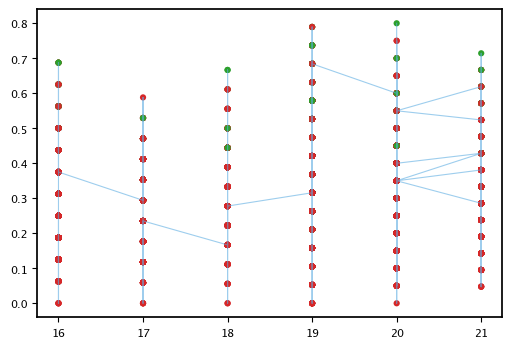

In [210]:
l_init = 40
t = 10000
nu = 0.01
kappa= 20
c = 50/(2*N)
t0 = 1000
seed = 42

set0 = evol(
    l_init, kappa, t, nu,
    c, gap, l0, f0, n, N,
    t0=t0, seed=seed, l_min=2, l_max=300,
    prefer_length=False,
    only_track_site=False
)

color_steps1 = [colors[x] for x in set1['ev_kind_step']]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(set1['ev_l_step'].astype(float), set1['ev_g_step'], color="#5dade2", lw=0.8, alpha=0.6)

ax.scatter(set1['ev_l_step'], set1['ev_g_step'], s=20, c=color_steps1, edgecolors="none", alpha=1)

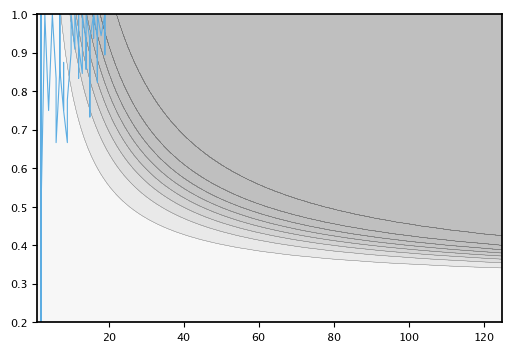

In [242]:
l_init = 20
t = 1000
nu = 0.01
kappa= 1
c = 100/(2*N)
t0 = 0
seed = 42

set1 = evol(
    l_init, kappa, t, nu,
    c, gap, l0, f0, n, N,
    t0=t0, seed=seed, l_min=2, l_max=300,
    prefer_length=False,
    only_track_site=False
)

color_steps1 = [colors[x] for x in set1['ev_kind_step']]

fig, ax = plt.subplots(figsize=(6, 4))
L, G, F = fitness_field(1, 125, 0.01, 0, gap, l0, f0, n)
draw_background(ax, L, G, F, Levels=8)
ax.plot(set1['ev_l_step'].astype(float), set1['ev_g_step'], color="#5dade2", lw=0.8)#, alpha=0.6)
#ax.scatter(set1['ev_l_step'], set1['ev_g_step'], s=20, c=color_steps1, edgecolors="none", alpha=1)

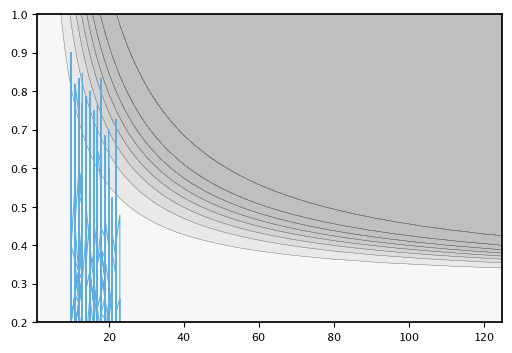

In [244]:
l_init = 20
t = 100000
nu = 0.01
kappa= 100
c = 1/(2*N)
t0 = 0
seed = 42

Set = evol(
    l_init, kappa, t, nu,
    c, gap, l0, f0, n, N,
    t0=t0, seed=seed, l_min=2, l_max=300,
    prefer_length=False,
    only_track_site=False
)

color_steps1 = [colors[x] for x in Set['ev_kind_step']]

fig, ax = plt.subplots(figsize=(6, 4))
draw_background(ax, L, G, F, Levels=8)
ax.plot(Set['ev_l_step'].astype(float), Set['ev_g_step'], color="#5dade2", lw=0.8)#, alpha=0.6)
#ax.scatter(set1['ev_l_step'], set1['ev_g_step'], s=20, c=color_steps1, edgecolors="none", alpha=1)

In [247]:
def count_step_types(x, y, tol=0.0):
    """
    Count steps that change only y (vertical; no change in x)
    vs. steps that change both x and y.

    Parameters
    ----------
    x, y : array-like, shape (N,)
        Trajectory coordinates.
    tol : float
        Tolerance for treating Δx or Δy as zero (use 0.0 for exact).

    Returns
    -------
    counts : dict
        {
          'vertical_only': int,   # Δx == 0 and Δy != 0
          'xy_change': int,       # Δx != 0 and Δy != 0
          'total': int,
          'frac_vertical_only': float,
          'frac_xy_change': float
        }
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if x.ndim != 1 or y.ndim != 1 or x.size != y.size or x.size < 2:
        raise ValueError("x/y must be 1D with the same length >= 2")

    dx = np.diff(x)
    dy = np.diff(y)

    # Zero tests (exact if tol=0.0; otherwise tolerance-based)
    zx = np.isclose(dx, 0.0, atol=tol, rtol=0.0)
    zy = np.isclose(dy, 0.0, atol=tol, rtol=0.0)

    # You said there are no steps with Δy == 0, but we still compute robustly.
    vertical_only = np.count_nonzero(zx & ~zy)     # Δx == 0 and Δy != 0
    xy_change     = np.count_nonzero(~zx & ~zy)    # Δx != 0 and Δy != 0

    total = dx.size
    return {
        "vertical_only": int(vertical_only),
        "xy_change": int(xy_change),
        "total": int(total),
        "frac_vertical_only": vertical_only / total if total else 0.0,
        "frac_xy_change": xy_change / total if total else 0.0,
    }

print(count_step_types(Set['ev_l_step'].astype(float), Set['ev_g_step'], tol=0.0))


{'vertical_only': 99924, 'xy_change': 75, 'total': 99999, 'frac_vertical_only': 0.999249992499925, 'frac_xy_change': 0.0007500075000750007}


In [253]:
l_init = 40
t = 100000
nu = 0.01
kappa= 10
c = 1/(2*N)
t0 = 100000
seed = 42

Set = evol(
    l_init, kappa, t, nu,
    c, gap, l0, f0, n, N,
    t0=t0, seed=seed, l_min=2, l_max=300,
    prefer_length=False,
    only_track_site=False
)
print(count_step_types(Set['ev_l_step'].astype(float), Set['ev_g_step'], tol=0.0))

{'vertical_only': 99177, 'xy_change': 822, 'total': 99999, 'frac_vertical_only': 0.991779917799178, 'frac_xy_change': 0.008220082200822008}


In [287]:
l_init = 40
t = 100000
nu = 0.01
kappa= 1
c = 1/(2*N)
t0 = 100000
seed = 42

Set = evol(
    l_init, kappa, t, nu,
    c, gap, l0, f0, n, N,
    t0=t0, seed=seed, l_min=2, l_max=300,
    prefer_length=False,
    only_track_site=False
)
print(count_step_types(Set['ev_l_step'].astype(float), Set['ev_g_step'], tol=0.0))

{'vertical_only': 98474, 'xy_change': 1525, 'total': 99999, 'frac_vertical_only': 0.9847498474984749, 'frac_xy_change': 0.015250152501525015}


In [288]:
Set['lengthchanges']

1525

In [289]:
np.sum(Set['ev_kind_step'] == 3) + np.sum(Set['ev_kind_step'] == 4) + np.sum(Set['ev_kind_step'] == 5) + np.sum(Set['ev_kind_step'] == 6)

np.int64(54970)

In [290]:
np.sum(Set['ev_kind_step'] == 0)

np.int64(0)